In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import os
print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

files = os.listdir("/content")

for file in files:
    print(file)

.config
drive
sample_data


In [ ]:
import pandas as pd

file_path = '/content/drive/MyDrive/Datasets and Dictionary-NYC/Datasets and Dictionary/trip_records/2023-1.parquet'

df = pd.read_parquet(file_path)

df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
0,2,2023-01-01 00:32:10,2023-01-01 00:40:36,1.0,0.97,1.0,N,161,141,2,9.3,1.00,0.5,0.00,0.0,1.0,14.30,2.5,0.00
1,2,2023-01-01 00:55:08,2023-01-01 01:01:27,1.0,1.10,1.0,N,43,237,1,7.9,1.00,0.5,4.00,0.0,1.0,16.90,2.5,0.00
2,2,2023-01-01 00:25:04,2023-01-01 00:37:49,1.0,2.51,1.0,N,48,238,1,14.9,1.00,0.5,15.00,0.0,1.0,34.90,2.5,0.00
3,1,2023-01-01 00:03:48,2023-01-01 00:13:25,0.0,1.90,1.0,N,138,7,1,12.1,7.25,0.5,0.00,0.0,1.0,20.85,0.0,1.25
4,2,2023-01-01 00:10:29,2023-01-01 00:21:19,1.0,1.43,1.0,N,107,79,1,11.4,1.00,0.5,3.28,0.0,1.0,19.68,2.5,0.00


In [ ]:
import pandas as pd
import glob

folder_path = '/content/drive/MyDrive/Datasets and Dictionary-NYC/Datasets and Dictionary/trip_records/'

files = glob.glob(folder_path + '*.parquet')

print("Number of files:", len(files))

Number of files: 12


In [ ]:
sampled_data = []

for file in files:
    data = pd.read_parquet(file)

    sample = data.sample(frac=0.10, random_state=42)

    sampled_data.append(sample)

    print(file.split('/')[-1], ":", len(data), "→", len(sample))

2023-9.parquet : 2817156 → 281716
2023-5.parquet : 2889185 → 288918
2023-6.parquet : 3258261 → 325826
2023-2.parquet : 3374086 → 337409
2023-1.parquet : 3041714 → 304171
2023-8.parquet : 2875947 → 287595
2023-7.parquet : 3481547 → 348155
2023-10.parquet : 3485185 → 348518
2023-3.parquet : 3275796 → 327580
2023-12.parquet : 3333925 → 333392
2023-4.parquet : 2792901 → 279290
2023-11.parquet : 3302857 → 330286


In [ ]:
df = pd.concat(sampled_data, ignore_index=True)

In [ ]:
df.shape

(3792856, 20)

In [ ]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,airport_fee
0,2,2023-09-30 01:39:21,2023-09-30 01:53:09,1.0,2.38,1.0,N,246,162,1,14.9,1.0,0.5,3.98,0.00,1.0,23.88,2.5,0.0,NaN
1,2,2023-09-02 04:10:38,2023-09-02 04:24:29,4.0,4.37,1.0,N,246,151,1,19.8,1.0,0.5,4.96,0.00,1.0,29.76,2.5,0.0,NaN
2,2,2023-09-11 07:21:33,2023-09-11 07:51:17,2.0,15.58,3.0,N,161,1,1,79.7,0.0,0.0,23.86,14.75,1.0,119.31,0.0,0.0,NaN
3,2,2023-09-28 18:24:58,2023-09-28 18:32:11,1.0,1.24,1.0,N,231,249,1,9.3,2.5,0.5,2.00,0.00,1.0,17.80,2.5,0.0,NaN
4,2,2023-09-30 23:48:50,2023-10-01 00:07:41,1.0,4.08,1.0,N,113,263,1,21.2,1.0,0.5,2.00,0.00,1.0,28.20,2.5,0.0,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3792856 entries, 0 to 3792855
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee           

In [ ]:
df.shape

(3792856, 20)

In [ ]:
random_state=42

In [ ]:
import pandas as pd
import glob

folder_path = '/content/drive/MyDrive/Datasets and Dictionary-NYC/Datasets and Dictionary/trip_records/'

files = glob.glob(folder_path + '*.parquet')

print("Number of files:", len(files))

Number of files: 12


In [ ]:
sampled_data = []

for file in files:
    data = pd.read_parquet(file)

    sample = data.sample(frac=0.10, random_state=42)

    sampled_data.append(sample)

    print(file.split('/')[-1], ":", len(data), "→", len(sample))

2023-9.parquet : 2817156 → 281716
2023-5.parquet : 2889185 → 288918
2023-6.parquet : 3258261 → 325826
2023-2.parquet : 3374086 → 337409
2023-1.parquet : 3041714 → 304171
2023-8.parquet : 2875947 → 287595
2023-7.parquet : 3481547 → 348155
2023-10.parquet : 3485185 → 348518
2023-3.parquet : 3275796 → 327580
2023-12.parquet : 3333925 → 333392
2023-4.parquet : 2792901 → 279290
2023-11.parquet : 3302857 → 330286


In [ ]:
df = pd.concat(sampled_data, ignore_index=True)

df.shape

(3792856, 20)

In [ ]:
df.index

RangeIndex(start=0, stop=3792856, step=1)

In [ ]:
df.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'store_and_fwd_flag',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'Airport_fee',
 'airport_fee']

In [ ]:
df[['Airport_fee', 'airport_fee']].isnull().sum()

,0
Airport_fee,426384
airport_fee,3495802


In [ ]:
df['airport_fee'].isnull().sum()

np.int64(3495802)

In [ ]:
df[['Airport_fee', 'airport_fee']].head(20)

,Airport_fee,airport_fee
0,0.00,NaN
1,0.00,NaN
2,0.00,NaN
3,0.00,NaN
4,0.00,NaN
5,0.00,NaN
6,0.00,NaN
7,0.00,NaN
8,0.00,NaN
9,0.00,NaN


In [ ]:
df[['Airport_fee', 'airport_fee']].notna().sum()

,0
Airport_fee,3366472
airport_fee,297054


In [ ]:
df['airport_fee'].notna().sum()

np.int64(297054)

In [ ]:
print("Non-null:", df['airport_fee'].notna().sum())
print("Missing:", df['airport_fee'].isna().sum())
print("Total:", len(df))

Non-null: 297054
Missing: 3495802
Total: 3792856


In [ ]:
df['airport_fee'] = df['airport_fee'].combine_first(df['Airport_fee'])

In [ ]:
print("Non-null:", df['airport_fee'].notna().sum())
print("Missing:", df['airport_fee'].isna().sum())
print("Total:", len(df))

Non-null: 3663526
Missing: 129330
Total: 3792856


In [ ]:
df.drop(columns=['Airport_fee'], inplace=True)

In [ ]:
df.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'store_and_fwd_flag',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'airport_fee']

In [ ]:
missing_percentage = df.isnull().mean() * 100

missing_percentage.sort_values(ascending=False)

,0
store_and_fwd_flag,3.409832
RatecodeID,3.409832
passenger_count,3.409832
airport_fee,3.409832
congestion_surcharge,3.409832
VendorID,0.000000
tpep_pickup_datetime,0.000000
tpep_dropoff_datetime,0.000000
DOLocationID,0.000000
PULocationID,0.000000


In [ ]:
df['passenger_count'].describe()

,passenger_count
count,3.663526e+06
mean,1.369947e+00
std,8.928825e-01
min,0.000000e+00
25%,1.000000e+00
50%,1.000000e+00
75%,1.000000e+00
max,9.000000e+00


In [ ]:
df['passenger_count'] = df['passenger_count'].fillna(
    df['passenger_count'].median()
)

In [ ]:
df['passenger_count'].isnull().sum()

np.int64(0)

In [ ]:
df['passenger_count'].value_counts().sort_index()

,count
passenger_count,
0.0,58256
1.0,2884386
2.0,555398
3.0,137700
4.0,77416
5.0,48045
6.0,31620
7.0,6
8.0,26


In [ ]:
df['RatecodeID'].value_counts(dropna=False).sort_index()

,count
RatecodeID,
1.0,3456963
2.0,144262
3.0,12327
4.0,7431
5.0,21050
6.0,4
99.0,21489
NaN,129330


In [ ]:
df['RatecodeID'] = df['RatecodeID'].fillna(
    df['RatecodeID'].mode()[0]
)

In [ ]:
df['RatecodeID'].isnull().sum()

np.int64(0)

In [ ]:
df['congestion_surcharge'].value_counts(dropna=False).sort_index()

,count
congestion_surcharge,
-2.5,147
0.0,279712
1.0,1
2.5,3383666
NaN,129330


In [ ]:
df['congestion_surcharge'] = df['congestion_surcharge'].fillna(
    df['congestion_surcharge'].mode()[0]
)

In [ ]:
df['congestion_surcharge'].isnull().sum()

np.int64(0)

In [ ]:
df['congestion_surcharge'].value_counts().sort_index()

,count
congestion_surcharge,
-2.5,147
0.0,279712
1.0,1
2.5,3512996


In [ ]:
df['payment_type'].value_counts(dropna=False).sort_index()

,count
payment_type,
0,129330
1,2987167
2,630992
3,17879
4,27488


In [ ]:
df[df['payment_type'] == 0][
    ['passenger_count',
     'RatecodeID',
     'fare_amount',
     'trip_distance',
     'tip_amount',
     'total_amount',
     'airport_fee',
     'congestion_surcharge']
].describe()

,passenger_count,RatecodeID,fare_amount,trip_distance,tip_amount,total_amount,airport_fee,congestion_surcharge
count,129330.0,129330.0,129330.000000,129330.000000,129330.000000,129330.000000,0.0,129330.0
mean,1.0,1.0,22.547232,20.013314,2.791303,29.887138,NaN,2.5
std,0.0,0.0,22.552296,1382.478538,3.440555,24.809857,NaN,0.0
min,1.0,1.0,0.000000,0.000000,0.000000,0.000000,NaN,2.5
25%,1.0,1.0,12.940000,0.620000,0.000000,19.020000,NaN,2.5
50%,1.0,1.0,18.720000,2.140000,2.030000,24.880000,NaN,2.5
75%,1.0,1.0,27.820000,4.480000,4.120000,34.860000,NaN,2.5
max,1.0,1.0,6339.000000,335004.330000,57.510000,6339.000000,NaN,2.5


In [ ]:
df['trip_distance'].describe()

,trip_distance
count,3.792856e+06
mean,4.128263e+00
std,2.651409e+02
min,0.000000e+00
25%,1.050000e+00
50%,1.800000e+00
75%,3.400000e+00
max,3.350043e+05


In [ ]:
Q1 = df['trip_distance'].quantile(0.25)
Q3 = df['trip_distance'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 1.05
Q3: 3.4
IQR: 2.3499999999999996
Lower bound: -2.4749999999999996
Upper bound: 6.924999999999999


In [ ]:
outliers_distance = df[df['trip_distance'] > upper_bound]

print("Number of outliers:", len(outliers_distance))
print("Percentage:", len(outliers_distance) / len(df) * 100)

Number of outliers: 500521
Percentage: 13.19641452246012


In [ ]:
df['trip_distance'].nlargest(20)

,trip_distance
428437,335004.33
1583466,186514.09
2666856,184152.27
996183,157733.41
3429995,106352.30
2782908,87934.50
1565966,78099.98
3287679,56823.80
932527,56561.11
1375129,52042.30


In [ ]:
df[df['trip_distance'] > 100][
    ['trip_distance', 'fare_amount', 'total_amount']
].describe()

,trip_distance,fare_amount,total_amount
count,124.000000,124.000000,124.000000
mean,20652.360806,158.461613,169.606290
std,41681.077779,297.132058,299.749612
min,100.800000,0.000000,1.500000
25%,1017.750000,15.742500,21.680000
50%,9673.930000,25.685000,32.905000
75%,22841.230000,72.190000,88.517500
max,335004.330000,1916.800000,1939.550000


In [ ]:
print("Trips > 100 miles:", (df['trip_distance'] > 100).sum())
print("Percentage:", (df['trip_distance'] > 100).mean() * 100)

Trips > 100 miles: 124
Percentage: 0.0032693041866076644


In [ ]:
df = df[df['trip_distance'] <= 100].copy()

In [ ]:
print(df.shape)
print(df['trip_distance'].max())

(3792732, 19)
98.56


In [ ]:
df['tip_amount'].describe()

,tip_amount
count,3.792732e+06
mean,3.553817e+00
std,4.064164e+00
min,0.000000e+00
25%,1.000000e+00
50%,2.850000e+00
75%,4.420000e+00
max,3.555000e+02


In [ ]:
Q1 = df['tip_amount'].quantile(0.25)
Q3 = df['tip_amount'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 1.0
Q3: 4.42
IQR: 3.42
Lower bound: -4.13
Upper bound: 9.55


In [ ]:
tip_outliers = df[df['tip_amount'] > 9.55]

print("Number of outliers:", len(tip_outliers))
print("Percentage:", len(tip_outliers) / len(df) * 100)

Number of outliers: 292562
Percentage: 7.713753568667651


In [ ]:
df['tip_amount'].nlargest(20)

,tip_amount
1737190,355.50
2545813,300.00
1624912,295.50
2023827,289.00
590003,288.00
557194,263.50
3422434,234.88
3087463,231.00
3502058,230.50
709675,222.22


In [ ]:
print("Tips > $100:", (df['tip_amount'] > 100).sum())
print("Percentage:", (df['tip_amount'] > 100).mean() * 100)

Tips > $100: 44
Percentage: 0.001160113606761564


In [ ]:
df[df['tip_amount'] > 100][
    ['tip_amount', 'fare_amount', 'total_amount', 'trip_distance']
].describe()

,tip_amount,fare_amount,total_amount,trip_distance
count,44.000000,44.000000,44.000000,44.000000
mean,157.109091,56.920682,220.223409,10.888182
std,68.499657,104.986698,115.138624,19.579239
min,100.010000,0.000000,111.500000,0.000000
25%,111.000000,3.000000,129.312500,0.000000
50%,120.500000,11.750000,182.875000,1.380000
75%,188.000000,70.000000,291.782500,16.727500
max,355.500000,500.000000,609.540000,94.100000


In [ ]:
df.shape

(3792732, 19)

In [ ]:
categorical_columns = [
    'VendorID',
    'RatecodeID',
    'store_and_fwd_flag',
    'PULocationID',
    'DOLocationID',
    'payment_type'
]

numerical_columns = [
    'passenger_count',
    'trip_distance',
    'fare_amount',
    'extra',
    'mta_tax',
    'tip_amount',
    'tolls_amount',
    'improvement_surcharge',
    'total_amount',
    'congestion_surcharge',
    'airport_fee'
]

datetime_columns = [
    'tpep_pickup_datetime',
    'tpep_dropoff_datetime'
]

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

print("\nDatetime columns:")
print(datetime_columns)

Categorical columns:
['VendorID', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type']

Numerical columns:
['passenger_count', 'trip_distance', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'airport_fee']

Datetime columns:
['tpep_pickup_datetime', 'tpep_dropoff_datetime']


In [ ]:
df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour

df['pickup_day'] = df['tpep_pickup_datetime'].dt.day_name()

df['pickup_day_num'] = df['tpep_pickup_datetime'].dt.dayofweek

df['pickup_month'] = df['tpep_pickup_datetime'].dt.month

In [ ]:
df[['tpep_pickup_datetime',
    'pickup_hour',
    'pickup_day',
    'pickup_month']].head()

,tpep_pickup_datetime,pickup_hour,pickup_day,pickup_month
0,2023-09-30 01:39:21,1,Saturday,9
1,2023-09-02 04:10:38,4,Saturday,9
2,2023-09-11 07:21:33,7,Monday,9
3,2023-09-28 18:24:58,18,Thursday,9
4,2023-09-30 23:48:50,23,Saturday,9


In [ ]:
hourly_pickups = df['pickup_hour'].value_counts().sort_index()

print(hourly_pickups)

pickup_hour
0     107620
1      71683
2      47751
3      31410
4      20972
5      22305
6      52679
7     103456
8     143119
9     162303
10    175442
11    191247
12    207806
13    213611
14    228825
15    235351
16    235264
17    255955
18    267965
19    239334
20    213012
21    212559
22    197491
23    155696
Name: count, dtype: int64


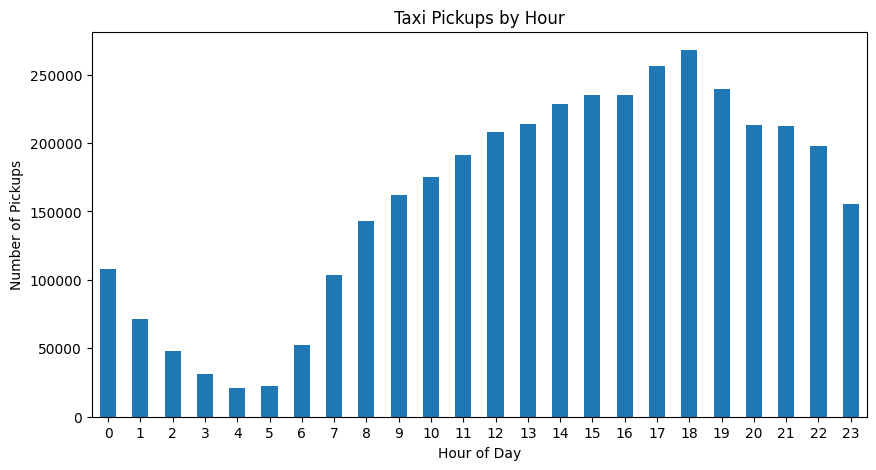

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

hourly_pickups.plot(kind='bar')

plt.title('Taxi Pickups by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Pickups')
plt.xticks(rotation=0)

plt.show()

In [ ]:
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_pickups = (
    df['pickup_day']
    .value_counts()
    .reindex(day_order)
)

print(daily_pickups)

pickup_day
Monday       472452
Tuesday      549414
Wednesday    582042
Thursday     594016
Friday       564106
Saturday     550903
Sunday       479923
Name: count, dtype: int64


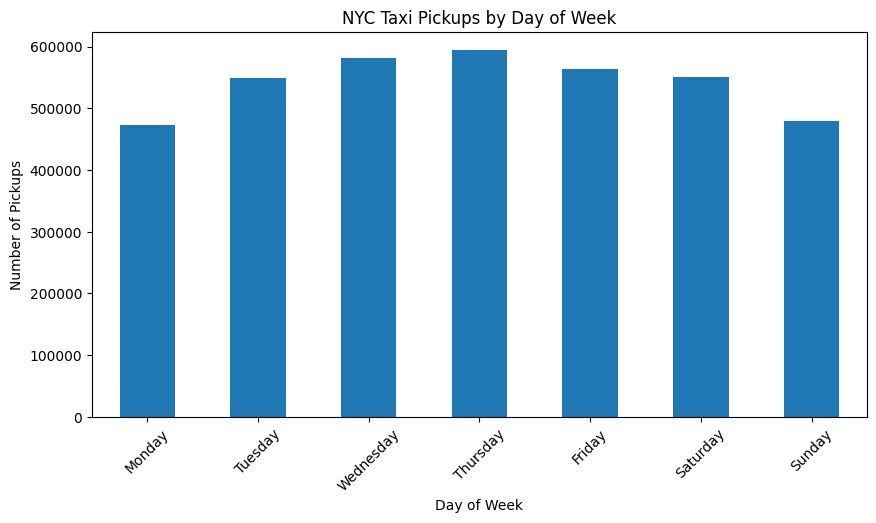

In [ ]:
plt.figure(figsize=(10, 5))

daily_pickups.plot(kind='bar')

plt.title('NYC Taxi Pickups by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Number of Pickups')
plt.xticks(rotation=45)

plt.show()

In [ ]:
peak_day = daily_pickups.idxmax()
peak_day_count = daily_pickups.max()

lowest_day = daily_pickups.idxmin()
lowest_day_count = daily_pickups.min()

print("Peak day:", peak_day, "-", peak_day_count)
print("Lowest day:", lowest_day, "-", lowest_day_count)

Peak day: Thursday - 593997
Lowest day: Monday - 472436


In [ ]:
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

monthly_pickups = (
    df['pickup_month']
    .value_counts()
    .reindex(month_order)
)

print(monthly_pickups)

pickup_month
January     NaN
February    NaN
March       NaN
April       NaN
May         NaN
June        NaN
July        NaN
August      NaN
September   NaN
October     NaN
November    NaN
December    NaN
Name: count, dtype: float64


In [ ]:
print(df['pickup_month'].unique())

[ 9 10 12  8  2  1  3  4  5  7  6 11]


In [ ]:
print(df.columns.tolist())

['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'airport_fee', 'pickup_hour', 'pickup_day', 'pickup_day_num', 'pickup_month']


In [ ]:
df['pickup_month'] = df['tpep_pickup_datetime'].dt.month_name()

In [ ]:
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

monthly_pickups = (
    df['pickup_month']
    .value_counts()
    .reindex(month_order)
)

print(monthly_pickups)

pickup_month
January      304170
February     288922
March        337401
April        325822
May          348162
June         327583
July         287591
August       279289
September    281716
October      348520
November     330285
December     333395
Name: count, dtype: int64


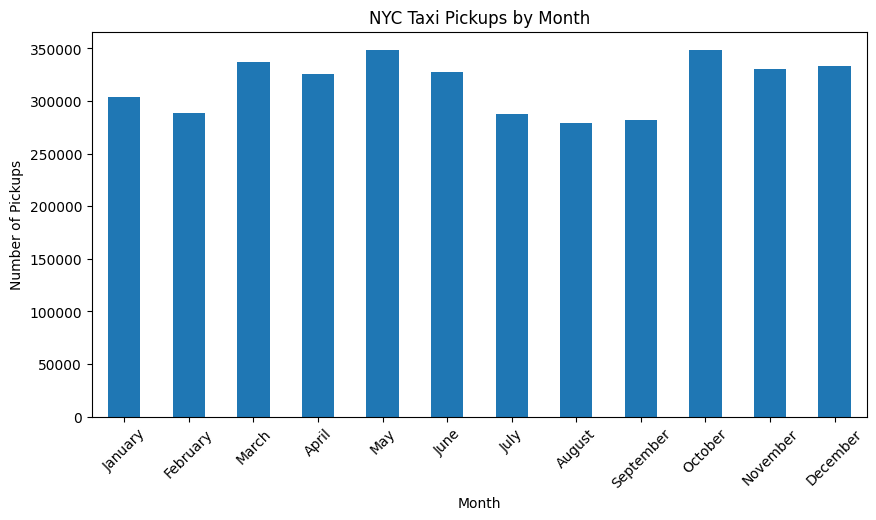

In [ ]:
plt.figure(figsize=(10, 5))
monthly_pickups.plot(kind='bar')
plt.title('NYC Taxi Pickups by Month')
plt.xlabel('Month')
plt.ylabel('Number of Pickups')
plt.xticks(rotation=45)
plt.show()

In [ ]:
peak_month = monthly_pickups.idxmax()
peak_month_count = monthly_pickups.max()

lowest_month = monthly_pickups.idxmin()
lowest_month_count = monthly_pickups.min()

print("Peak month:", peak_month, "-", peak_month_count)
print("Lowest month:", lowest_month, "-", lowest_month_count)

Peak month: October - 348520
Lowest month: August - 279289


In [ ]:
financial_cols = ['fare_amount', 'tip_amount', 'total_amount', 'trip_distance']

for col in financial_cols:
    zero_count = (df[col] == 0).sum()
    negative_count = (df[col] < 0).sum()
    print(f"{col}: {zero_count} zeros, {negative_count} negatives")

fare_amount: 1283 zeros, 0 negatives
tip_amount: 869187 zeros, 0 negatives
total_amount: 573 zeros, 220 negatives
trip_distance: 73376 zeros, 0 negatives


In [ ]:
df_nonzero = df[
    (df['fare_amount'] > 0) &
    (df['total_amount'] > 0) &
    (df['trip_distance'] > 0)
].copy()

print("Original rows:", len(df))
print("Rows after filtering:", len(df_nonzero))
print("Rows dropped:", len(df) - len(df_nonzero))

Original rows: 3792856
Rows after filtering: 3718818
Rows dropped: 74038


In [ ]:
df_nonzero['pickup_month'] = df_nonzero['tpep_pickup_datetime'].dt.month_name()

month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

monthly_revenue = (
    df_nonzero.groupby('pickup_month')['total_amount']
    .sum()
    .reindex(month_order)
)

print(monthly_revenue)

pickup_month
January       8198763.24
February      7774926.00
March         9382515.00
April         9204763.12
May          10087704.16
June          9496728.95
July          8221487.96
August        7983753.34
September     8217722.71
October      10037988.77
November      9366965.37
December      9502696.17
Name: total_amount, dtype: float64


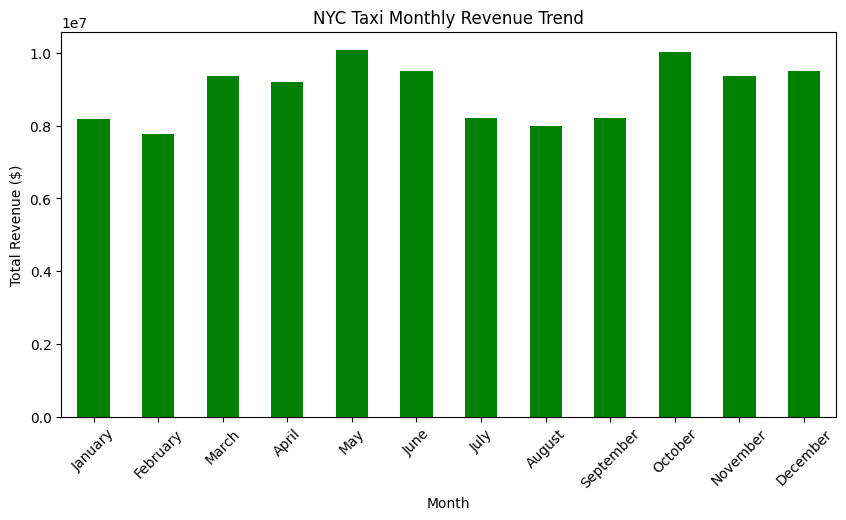

In [ ]:
plt.figure(figsize=(10, 5))
monthly_revenue.plot(kind='bar', color='green')
plt.title('NYC Taxi Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue ($)')
plt.xticks(rotation=45)
plt.show()

In [ ]:
df_nonzero['pickup_quarter'] = df_nonzero['tpep_pickup_datetime'].dt.quarter

quarterly_revenue = df_nonzero.groupby('pickup_quarter')['total_amount'].sum()
quarterly_share = (quarterly_revenue / quarterly_revenue.sum() * 100).round(2)

print(quarterly_revenue)
print()
print(quarterly_share)

pickup_quarter
1    25356204.24
2    28789196.23
3    24422964.01
4    28907650.31
Name: total_amount, dtype: float64

pickup_quarter
1    23.59
2    26.79
3    22.72
4    26.90
Name: total_amount, dtype: float64


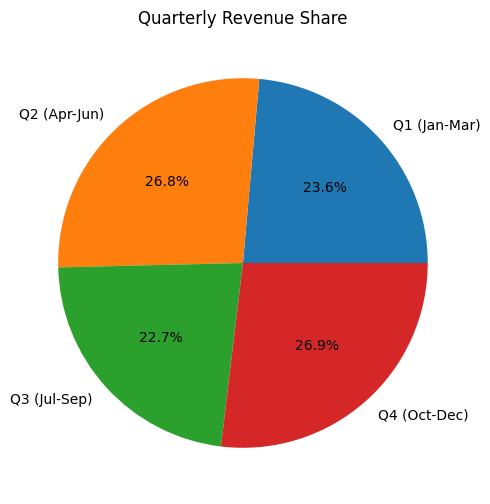

In [ ]:
plt.figure(figsize=(6, 6))
quarterly_share.plot(
    kind='pie',
    autopct='%1.1f%%',
    labels=['Q1 (Jan-Mar)', 'Q2 (Apr-Jun)', 'Q3 (Jul-Sep)', 'Q4 (Oct-Dec)'],
    ylabel=''
)
plt.title('Quarterly Revenue Share')
plt.show()

Correlation between trip_distance and fare_amount: 0.9421568367767784


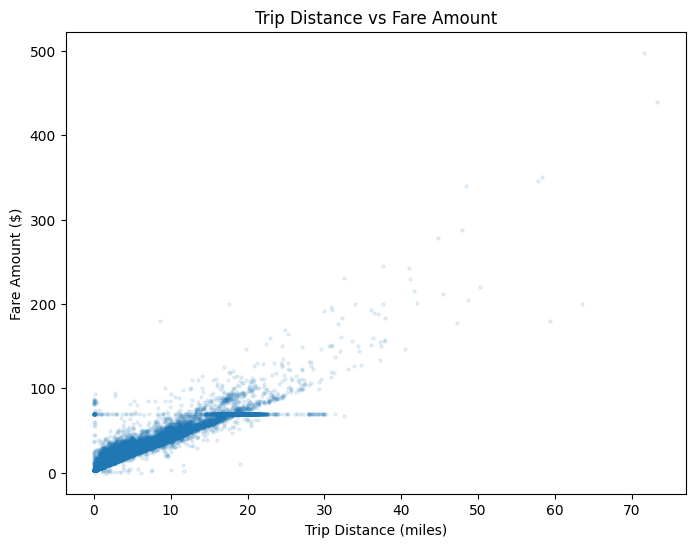

In [ ]:
# Correlation between trip_distance and fare_amount
correlation = df_nonzero['trip_distance'].corr(df_nonzero['fare_amount'])
print("Correlation between trip_distance and fare_amount:", correlation)

# Scatter plot (sampling for speed given 3.7M rows)
sample_df = df_nonzero.sample(50000, random_state=42)

plt.figure(figsize=(8, 6))
plt.scatter(sample_df['trip_distance'], sample_df['fare_amount'], alpha=0.1, s=5)
plt.title('Trip Distance vs Fare Amount')
plt.xlabel('Trip Distance (miles)')
plt.ylabel('Fare Amount ($)')
plt.show()

In [ ]:
print(df_nonzero['trip_distance'].describe())
print()
print(df_nonzero['fare_amount'].describe())

count    3.718695e+06
mean     3.521002e+00
std      4.553559e+00
min      1.000000e-02
25%      1.100000e+00
50%      1.810000e+00
75%      3.480000e+00
max      9.856000e+01
Name: trip_distance, dtype: float64

count    3.718695e+06
mean     1.976022e+01
std      1.791543e+01
min      1.000000e-02
25%      9.300000e+00
50%      1.350000e+01
75%      2.190000e+01
max      2.194700e+03
Name: fare_amount, dtype: float64


In [ ]:
suspicious = df_nonzero[
    (df_nonzero['trip_distance'] > 50) | (df_nonzero['fare_amount'] > 200)
]
print("Number of suspicious rows:", len(suspicious))
print(suspicious[['trip_distance', 'fare_amount']].sort_values('trip_distance', ascending=False).head(20))

Number of suspicious rows: 1215
         trip_distance  fare_amount
3726393          98.56        150.0
935971           98.52        300.0
3189425          97.69        350.0
3595633          96.85        559.0
2909937          96.80        540.0
648127           96.27        450.0
2537775          94.40        300.0
2301023          94.10        500.0
1796940          93.80        350.0
250471           91.65        617.6
2262604          91.10        235.4
2811145          89.36        515.4
1565333          89.15        400.0
957444           88.85        260.0
2308076          87.74        229.8
3679270          87.43        565.0
1121164          86.45        524.5
1067299          86.45        502.1
3295344          86.23          3.0
1624277          85.70        528.7


In [ ]:
df_trimmed = df_nonzero[
    (df_nonzero['trip_distance'] <= 50) & (df_nonzero['fare_amount'] <= 200)
]

trimmed_corr = df_trimmed['trip_distance'].corr(df_trimmed['fare_amount'])
print("Rows before trimming:", len(df_nonzero))
print("Rows after trimming:", len(df_trimmed))
print("Correlation after trimming outliers:", trimmed_corr)

Rows before trimming: 3718695
Rows after trimming: 3717480
Correlation after trimming outliers: 0.947915116770829


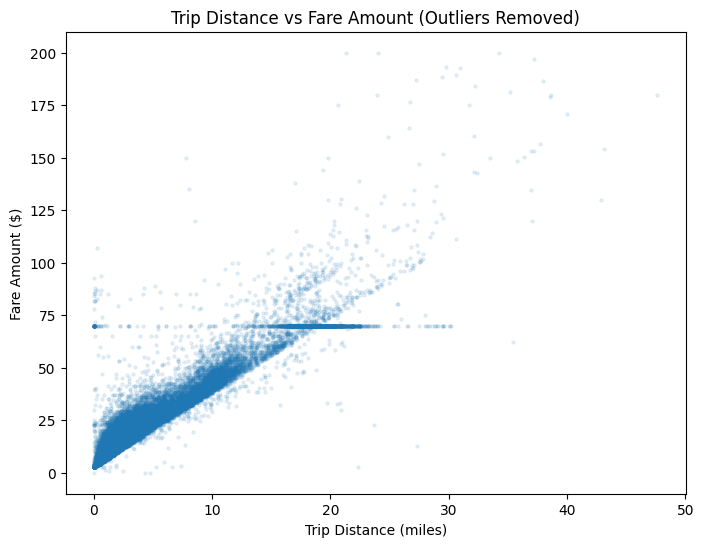

In [ ]:
sample_df = df_trimmed.sample(50000, random_state=42)

plt.figure(figsize=(8, 6))
plt.scatter(sample_df['trip_distance'], sample_df['fare_amount'], alpha=0.1, s=5)
plt.title('Trip Distance vs Fare Amount (Outliers Removed)')
plt.xlabel('Trip Distance (miles)')
plt.ylabel('Fare Amount ($)')
plt.show()

In [ ]:
df_trimmed = df_trimmed.copy()
df_trimmed['trip_duration_min'] = (
    df_trimmed['tpep_dropoff_datetime'] - df_trimmed['tpep_pickup_datetime']
).dt.total_seconds() / 60

print(df_trimmed['trip_duration_min'].describe())

count    3.717480e+06
mean     1.755657e+01
std      4.089147e+01
min     -6.493333e+01
25%      7.766667e+00
50%      1.275000e+01
75%      2.073333e+01
max      7.053617e+03
Name: trip_duration_min, dtype: float64


In [ ]:
bad_duration = df_trimmed[
    (df_trimmed['trip_duration_min'] <= 0) | (df_trimmed['trip_duration_min'] > 180)
]
print("Number of suspicious duration rows:", len(bad_duration))
print(bad_duration[['tpep_pickup_datetime', 'tpep_dropoff_datetime', 'trip_duration_min']].head(10))

Number of suspicious duration rows: 3729
      tpep_pickup_datetime tpep_dropoff_datetime  trip_duration_min
797    2023-09-17 16:09:55   2023-09-17 16:09:33          -0.366667
889    2023-09-15 11:44:19   2023-09-16 11:37:53        1433.566667
2813   2023-09-15 15:21:47   2023-09-16 00:00:00         518.216667
3537   2023-09-26 22:15:45   2023-09-27 22:11:44        1435.983333
6182   2023-09-05 14:05:31   2023-09-06 00:00:00         594.483333
10224  2023-09-04 16:26:14   2023-09-05 15:43:58        1397.733333
16592  2023-09-03 04:15:15   2023-09-04 03:55:08        1419.883333
17044  2023-09-12 22:54:17   2023-09-13 22:48:02        1433.750000
17543  2023-09-29 14:06:44   2023-09-29 17:19:04         192.333333
17771  2023-09-15 15:17:21   2023-09-16 14:42:29        1405.133333


In [ ]:
df_trimmed = df_trimmed[
    (df_trimmed['trip_duration_min'] > 0) & (df_trimmed['trip_duration_min'] <= 180)
].copy()

print("Rows after duration filtering:", len(df_trimmed))
print(df_trimmed['trip_duration_min'].describe())

Rows after duration filtering: 3713751
count    3.713751e+06
mean     1.644597e+01
std      1.312755e+01
min      1.666667e-02
25%      7.766667e+00
50%      1.273333e+01
75%      2.070000e+01
max      1.799833e+02
Name: trip_duration_min, dtype: float64


In [ ]:
# 1. fare_amount vs trip_duration_min
corr_fare_duration = df_trimmed['fare_amount'].corr(df_trimmed['trip_duration_min'])
print("Correlation - fare_amount vs trip_duration:", corr_fare_duration)

# 2. fare_amount vs passenger_count
corr_fare_passengers = df_trimmed['fare_amount'].corr(df_trimmed['passenger_count'])
print("Correlation - fare_amount vs passenger_count:", corr_fare_passengers)

# 3. tip_amount vs trip_distance
corr_tip_distance = df_trimmed['tip_amount'].corr(df_trimmed['trip_distance'])
print("Correlation - tip_amount vs trip_distance:", corr_tip_distance)

Correlation - fare_amount vs trip_duration: 0.8550058720890302
Correlation - fare_amount vs passenger_count: 0.04254359057447425
Correlation - tip_amount vs trip_distance: 0.5944279728098653


Step — Visualize each **relationship** bold text

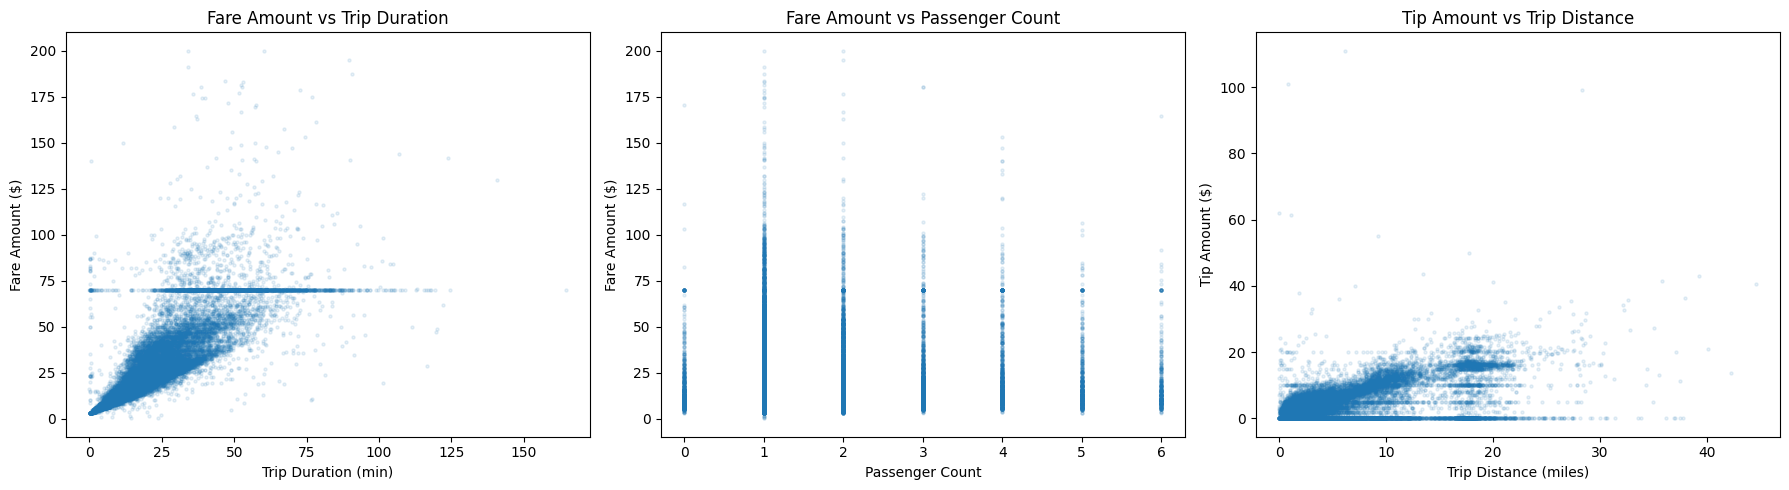

In [ ]:
sample_df = df_trimmed.sample(50000, random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(sample_df['trip_duration_min'], sample_df['fare_amount'], alpha=0.1, s=5)
axes[0].set_title('Fare Amount vs Trip Duration')
axes[0].set_xlabel('Trip Duration (min)')
axes[0].set_ylabel('Fare Amount ($)')

axes[1].scatter(sample_df['passenger_count'], sample_df['fare_amount'], alpha=0.1, s=5)
axes[1].set_title('Fare Amount vs Passenger Count')
axes[1].set_xlabel('Passenger Count')
axes[1].set_ylabel('Fare Amount ($)')

axes[2].scatter(sample_df['trip_distance'], sample_df['tip_amount'], alpha=0.1, s=5)
axes[2].set_title('Tip Amount vs Trip Distance')
axes[2].set_xlabel('Trip Distance (miles)')
axes[2].set_ylabel('Tip Amount ($)')

plt.tight_layout()
plt.show()

3.1.8 — Payment type distribution. Run:

payment_type_label
Credit card    2957854
Cash            617685
Dispute          24590
No charge        13481
Name: count, dtype: int64


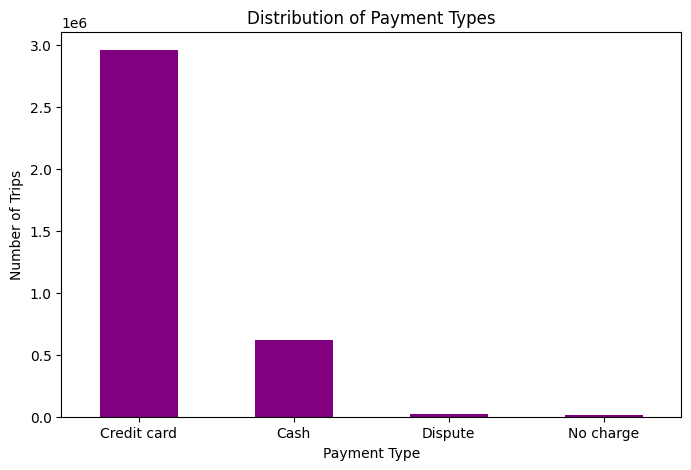

In [ ]:
payment_map = {1: 'Credit card', 2: 'Cash', 3: 'No charge', 4: 'Dispute'}
df_trimmed['payment_type_label'] = df_trimmed['payment_type'].map(payment_map)

payment_dist = df_trimmed['payment_type_label'].value_counts()
print(payment_dist)

plt.figure(figsize=(8, 5))
payment_dist.plot(kind='bar', color='purple')
plt.title('Distribution of Payment Types')
plt.xlabel('Payment Type')
plt.ylabel('Number of Trips')
plt.xticks(rotation=0)
plt.show()

Load the shapefile with the correct path

In [ ]:
import os

for root, dirs, files in os.walk('/'):
    for file in files:
        if file == 'taxi_zones.shp':
            print(os.path.join(root, file))

/content/drive/MyDrive/Datasets and Dictionary-NYC/Datasets and Dictionary/taxi_zones/taxi_zones.shp


In [ ]:
import geopandas as gpd

zones = gpd.read_file('/content/drive/MyDrive/Datasets and Dictionary-NYC/Datasets and Dictionary/taxi_zones/taxi_zones.shp')
zones.head()

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20..."
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144..."


Step — Plot the zones

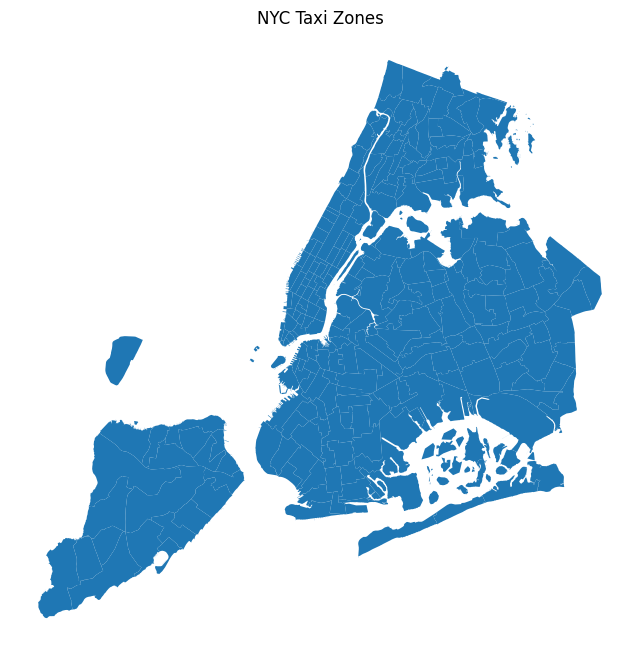

In [ ]:
zones.plot(figsize=(8, 10))
plt.title('NYC Taxi Zones')
plt.axis('off')
plt.show()

3.1.10 — Merge zones data into trip data

In [ ]:
merged_df = df_trimmed.merge(
    zones[['LocationID', 'zone', 'borough']],
    left_on='PULocationID',
    right_on='LocationID',
    how='left'
)

print(merged_df.shape)
merged_df.head()

(3713971, 29)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,pickup_hour,pickup_day,pickup_day_num,pickup_month,pickup_quarter,trip_duration_min,payment_type_label,LocationID,zone,borough
0,2,2023-09-30 01:39:21,2023-09-30 01:53:09,1.0,2.38,1.0,N,246,162,1,...,1,Saturday,5,September,3,13.800000,Credit card,246.0,West Chelsea/Hudson Yards,Manhattan
1,2,2023-09-02 04:10:38,2023-09-02 04:24:29,4.0,4.37,1.0,N,246,151,1,...,4,Saturday,5,September,3,13.850000,Credit card,246.0,West Chelsea/Hudson Yards,Manhattan
2,2,2023-09-11 07:21:33,2023-09-11 07:51:17,2.0,15.58,3.0,N,161,1,1,...,7,Monday,0,September,3,29.733333,Credit card,161.0,Midtown Center,Manhattan
3,2,2023-09-28 18:24:58,2023-09-28 18:32:11,1.0,1.24,1.0,N,231,249,1,...,18,Thursday,3,September,3,7.216667,Credit card,231.0,TriBeCa/Civic Center,Manhattan
4,2,2023-09-30 23:48:50,2023-10-01 00:07:41,1.0,4.08,1.0,N,113,263,1,...,23,Saturday,5,September,3,18.850000,Credit card,113.0,Greenwich Village North,Manhattan


Step — Check for duplicate LocationIDs in zones

In [ ]:
print("Duplicate LocationIDs in zones:", zones['LocationID'].duplicated().sum())
print(zones[zones['LocationID'].duplicated(keep=False)].sort_values('LocationID'))

Duplicate LocationIDs in zones: 3
     OBJECTID  Shape_Leng  Shape_Area  \
55         56    0.056848    0.000181   
56         57    0.019271    0.000018   
102       103    0.014306    0.000006   
103       104    0.021221    0.000012   
104       105    0.077425    0.000369   

                                              zone  LocationID    borough  \
55                                          Corona          56     Queens   
56                                          Corona          56     Queens   
102  Governor's Island/Ellis Island/Liberty Island         103  Manhattan   
103  Governor's Island/Ellis Island/Liberty Island         103  Manhattan   
104  Governor's Island/Ellis Island/Liberty Island         103  Manhattan   

                                              geometry  
55   POLYGON ((1024813.399 211643.796, 1024910.997 ...  
56   POLYGON ((1025447.751 212499.788, 1024585.351 ...  
102  POLYGON ((972079.575 190732.429, 972184.766 19...  
103  POLYGON ((973172.666 19

Step — Dissolve duplicate zones into one row per LocationID

In [ ]:
zones = zones.dissolve(by='LocationID', as_index=False, aggfunc={
    'OBJECTID': 'first',
    'Shape_Leng': 'sum',
    'Shape_Area': 'sum',
    'zone': 'first',
    'borough': 'first'
})

print("Duplicate LocationIDs after dissolve:", zones['LocationID'].duplicated().sum())
print(zones.shape)

Duplicate LocationIDs after dissolve: 0
(260, 7)


Step — Redo the merge with fixed zones

In [ ]:
merged_df = df_trimmed.merge(
    zones[['LocationID', 'zone', 'borough']],
    left_on='PULocationID',
    right_on='LocationID',
    how='left'
)

print("df_trimmed rows:", len(df_trimmed))
print("merged_df rows:", len(merged_df))

df_trimmed rows: 3713751
merged_df rows: 3713751


3.1.11 — Group by location to find total trips per zone

In [ ]:
trips_per_zone = (
    merged_df.groupby(['PULocationID', 'zone', 'borough'])
    .size()
    .reset_index(name='trip_count')
    .sort_values('trip_count', ascending=False)
)

print(trips_per_zone.head(10))

     PULocationID                          zone    borough  trip_count
125           132                   JFK Airport     Queens      190238
228           237         Upper East Side South  Manhattan      176514
154           161                Midtown Center  Manhattan      173003
227           236         Upper East Side North  Manhattan      157158
155           162                  Midtown East  Manhattan      132592
131           138             LaGuardia Airport     Queens      127908
178           186  Penn Station/Madison Sq West  Manhattan      127513
221           230     Times Sq/Theatre District  Manhattan      124143
135           142           Lincoln Square East  Manhattan      122870
163           170                   Murray Hill  Manhattan      110631


3.1.12 — Add trip counts to zones GeoDataFrame

In [ ]:
zones_with_trips = zones.merge(
    trips_per_zone[['PULocationID', 'trip_count']],
    left_on='LocationID',
    right_on='PULocationID',
    how='left'
)

zones_with_trips['trip_count'] = zones_with_trips['trip_count'].fillna(0)
zones_with_trips.head()

,LocationID,geometry,OBJECTID,Shape_Leng,Shape_Area,zone,borough,PULocationID,trip_count
0,1,"POLYGON ((933100.918 192536.086, 933091.011 19...",1,0.116357,0.000782,Newark Airport,EWR,1.0,112.0
1,2,"MULTIPOLYGON (((1020447.262 151454.148, 102035...",2,0.433470,0.004866,Jamaica Bay,Queens,2.0,8.0
2,3,"POLYGON ((1026308.77 256767.698, 1026495.593 2...",3,0.084341,0.000314,Allerton/Pelham Gardens,Bronx,3.0,67.0
3,4,"POLYGON ((992073.467 203714.076, 992068.667 20...",4,0.043567,0.000112,Alphabet City,Manhattan,4.0,4430.0
4,5,"POLYGON ((935843.31 144283.336, 936046.565 144...",5,0.092146,0.000498,Arden Heights,Staten Island,5.0,29.0


3.1.13 — Plot the choropleth map

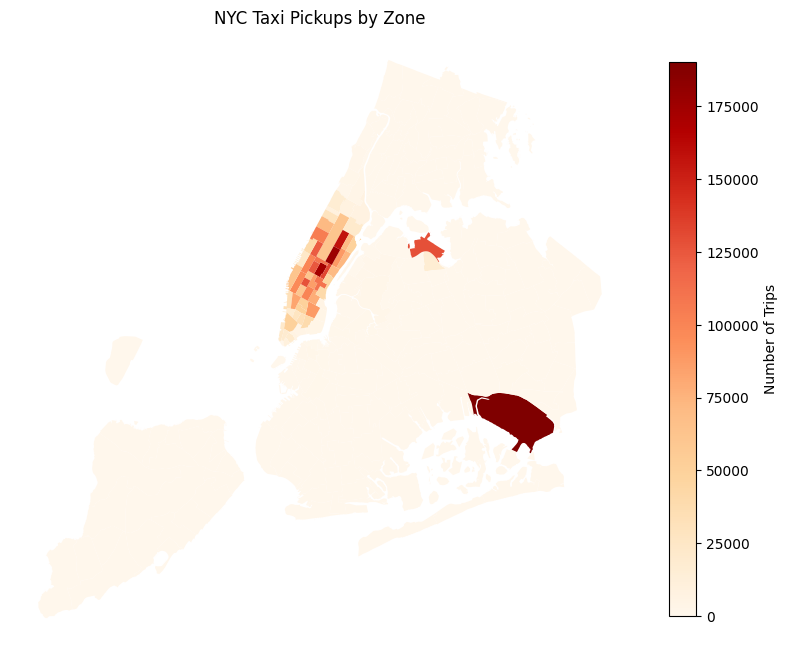

In [ ]:
fig, ax = plt.subplots(figsize=(10, 12))

zones_with_trips.plot(
    column='trip_count',
    ax=ax,
    legend=True,
    cmap='OrRd',
    legend_kwds={'label': 'Number of Trips', 'shrink': 0.6}
)

plt.title('NYC Taxi Pickups by Zone')
plt.axis('off')
plt.show()

3.1.13 — Choropleth interpretation

In [ ]:
zones_with_trips_sorted = zones_with_trips[['zone', 'borough', 'trip_count']].sort_values('trip_count', ascending=False)
print(zones_with_trips_sorted.head(15))
print(zones_with_trips_sorted.tail(10))

                             zone    borough  trip_count
128                   JFK Airport     Queens    190238.0
233         Upper East Side South  Manhattan    176514.0
157                Midtown Center  Manhattan    173003.0
232         Upper East Side North  Manhattan    157158.0
158                  Midtown East  Manhattan    132592.0
134             LaGuardia Airport     Queens    127908.0
182  Penn Station/Madison Sq West  Manhattan    127513.0
226     Times Sq/Theatre District  Manhattan    124143.0
138           Lincoln Square East  Manhattan    122870.0
166                   Murray Hill  Manhattan    110631.0
159                 Midtown North  Manhattan    108552.0
235         Upper West Side South  Manhattan    104306.0
230                      Union Sq  Manhattan    100580.0
47                   Clinton East  Manhattan     99143.0
66                   East Chelsea  Manhattan     97005.0
                                              zone        borough  trip_count
152       

3.2.1 — Average speed by route and hour

In [ ]:
merged_df['pickup_hour'] = merged_df['tpep_pickup_datetime'].dt.hour
merged_df['speed_mph'] = merged_df['trip_distance'] / (merged_df['trip_duration_min'] / 60)

route_speed = (
    merged_df.groupby(['PULocationID', 'DOLocationID', 'pickup_hour'])['speed_mph']
    .mean()
    .reset_index()
)

# Filter to routes with a reasonable number of trips for reliability
route_counts = merged_df.groupby(['PULocationID', 'DOLocationID', 'pickup_hour']).size().reset_index(name='trip_count')
route_speed = route_speed.merge(route_counts, on=['PULocationID', 'DOLocationID', 'pickup_hour'])
route_speed_reliable = route_speed[route_speed['trip_count'] >= 20]

slowest_routes = route_speed_reliable.sort_values('speed_mph').head(15)
print(slowest_routes)

        PULocationID  DOLocationID  pickup_hour  speed_mph  trip_count
117424           186           100           12   3.540726         183
117425           186           100           13   3.569387         157
117423           186           100           11   3.815705         161
118439           186           186           13   3.893779          66
117428           186           100           16   4.074448         134
118922           186           230           12   4.109775         636
88308            144           144           16   4.118966          32
117427           186           100           15   4.154893         142
88309            144           144           17   4.159247          29
100811           161           230           17   4.160655         420
118923           186           230           13   4.161997         587
117422           186           100           10   4.162152         120
103634           162           230           17   4.202972         342
111986

Step — Map zone IDs to names for context

In [ ]:
zone_lookup = zones.set_index('LocationID')['zone'].to_dict()

slowest_routes = slowest_routes.copy()
slowest_routes['pickup_zone'] = slowest_routes['PULocationID'].map(zone_lookup)
slowest_routes['dropoff_zone'] = slowest_routes['DOLocationID'].map(zone_lookup)

print(slowest_routes[['pickup_zone', 'dropoff_zone', 'pickup_hour', 'speed_mph', 'trip_count']])

                         pickup_zone                  dropoff_zone  \
117424  Penn Station/Madison Sq West              Garment District   
117425  Penn Station/Madison Sq West              Garment District   
117423  Penn Station/Madison Sq West              Garment District   
118439  Penn Station/Madison Sq West  Penn Station/Madison Sq West   
117428  Penn Station/Madison Sq West              Garment District   
118922  Penn Station/Madison Sq West     Times Sq/Theatre District   
88308            Little Italy/NoLiTa           Little Italy/NoLiTa   
117427  Penn Station/Madison Sq West              Garment District   
88309            Little Italy/NoLiTa           Little Italy/NoLiTa   
100811                Midtown Center     Times Sq/Theatre District   
118923  Penn Station/Madison Sq West     Times Sq/Theatre District   
117422  Penn Station/Madison Sq West              Garment District   
103634                  Midtown East     Times Sq/Theatre District   
111986              

3.2.2 — Trips per hour with busiest hour identified

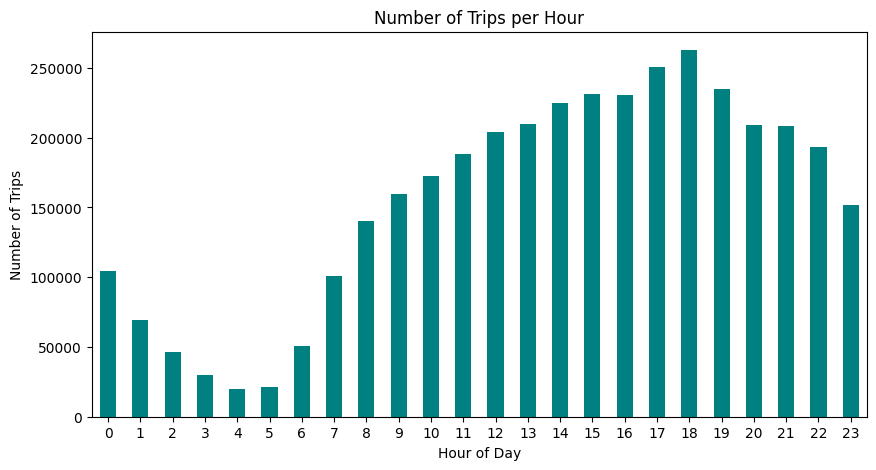

Busiest hour: 18:00 with 262758 trips


In [ ]:
hourly_trips_detailed = merged_df.groupby('pickup_hour').size()

plt.figure(figsize=(10, 5))
hourly_trips_detailed.plot(kind='bar', color='teal')
plt.title('Number of Trips per Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Trips')
plt.xticks(rotation=0)
plt.show()

busiest_hour = hourly_trips_detailed.idxmax()
busiest_hour_count = hourly_trips_detailed.max()
print(f"Busiest hour: {busiest_hour}:00 with {busiest_hour_count} trips")

In [ ]:
# Estimate based on known annual total (~38.3M trips for 2023 NYC yellow taxi)
estimated_total_2023_trips = 38_310_226  # approximate, can verify via TLC records
sample_fraction_estimated = len(df) / estimated_total_2023_trips
print("Estimated sampling fraction:", sample_fraction_estimated)

Estimated sampling fraction: 0.09900051229141796


3.2.3 — Scale up trip counts for the 5 busiest hours

In [ ]:
sample_fraction = 0.0793969213337452

top_5_hours = hourly_trips_detailed.sort_values(ascending=False).head(5)
top_5_hours_scaled = (top_5_hours / sample_fraction).round(0)

print("Top 5 busiest hours (sampled counts):")
print(top_5_hours)
print()
print("Top 5 busiest hours (estimated actual counts):")
print(top_5_hours_scaled)

Top 5 busiest hours (sampled counts):
pickup_hour
18    262758
17    250914
19    234972
15    230961
16    230707
dtype: int64

Top 5 busiest hours (estimated actual counts):
pickup_hour
18    3309423.0
17    3160248.0
19    2959460.0
15    2908942.0
16    2905742.0
dtype: float64


3.2.4 — Weekday vs weekend hourly comparison

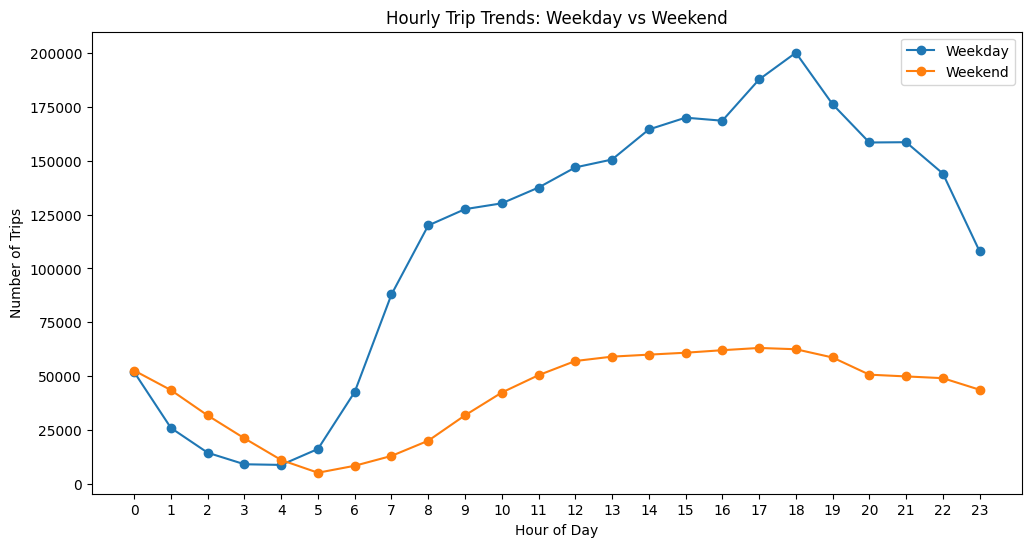

In [ ]:
merged_df['is_weekend'] = merged_df['tpep_pickup_datetime'].dt.dayofweek >= 5

weekday_hourly = merged_df[~merged_df['is_weekend']].groupby('pickup_hour').size()
weekend_hourly = merged_df[merged_df['is_weekend']].groupby('pickup_hour').size()

plt.figure(figsize=(12, 6))
plt.plot(weekday_hourly.index, weekday_hourly.values, label='Weekday', marker='o')
plt.plot(weekend_hourly.index, weekend_hourly.values, label='Weekend', marker='o')
plt.title('Hourly Trip Trends: Weekday vs Weekend')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Trips')
plt.legend()
plt.xticks(range(0, 24))
plt.show()

3.2.5
Identify the top 10 zones with high hourly pickups and drops

Step 1 — Count pickups by zone

In [ ]:
pickup_zone_counts = df['PULocationID'].value_counts()

print(pickup_zone_counts.head(10))

PULocationID
132    195086
237    178158
161    175056
236    158975
162    133999
138    129204
186    128863
230    126195
142    124524
170    112247
Name: count, dtype: int64


In [ ]:
dropoff_zone_counts = df['DOLocationID'].value_counts()

print(dropoff_zone_counts.head(10))

DOLocationID
236    166491
237    159564
161    147181
230    116698
170    111479
162    106893
142    106019
239    105739
141     99571
68      96022
Name: count, dtype: int64


3.2.5 visualization

In [ ]:
# Top 10 pickup zones
top_10_pickup_zones = df['PULocationID'].value_counts().head(10)

# Top 10 drop-off zones
top_10_dropoff_zones = df['DOLocationID'].value_counts().head(10)

print("Top 10 Pickup Zones:")
print(top_10_pickup_zones)

print("\nTop 10 Drop-off Zones:")
print(top_10_dropoff_zones)

Top 10 Pickup Zones:
PULocationID
132    195086
237    178158
161    175056
236    158975
162    133999
138    129204
186    128863
230    126195
142    124524
170    112247
Name: count, dtype: int64

Top 10 Drop-off Zones:
DOLocationID
236    166491
237    159564
161    147181
230    116698
170    111479
162    106893
142    106019
239    105739
141     99571
68      96022
Name: count, dtype: int64


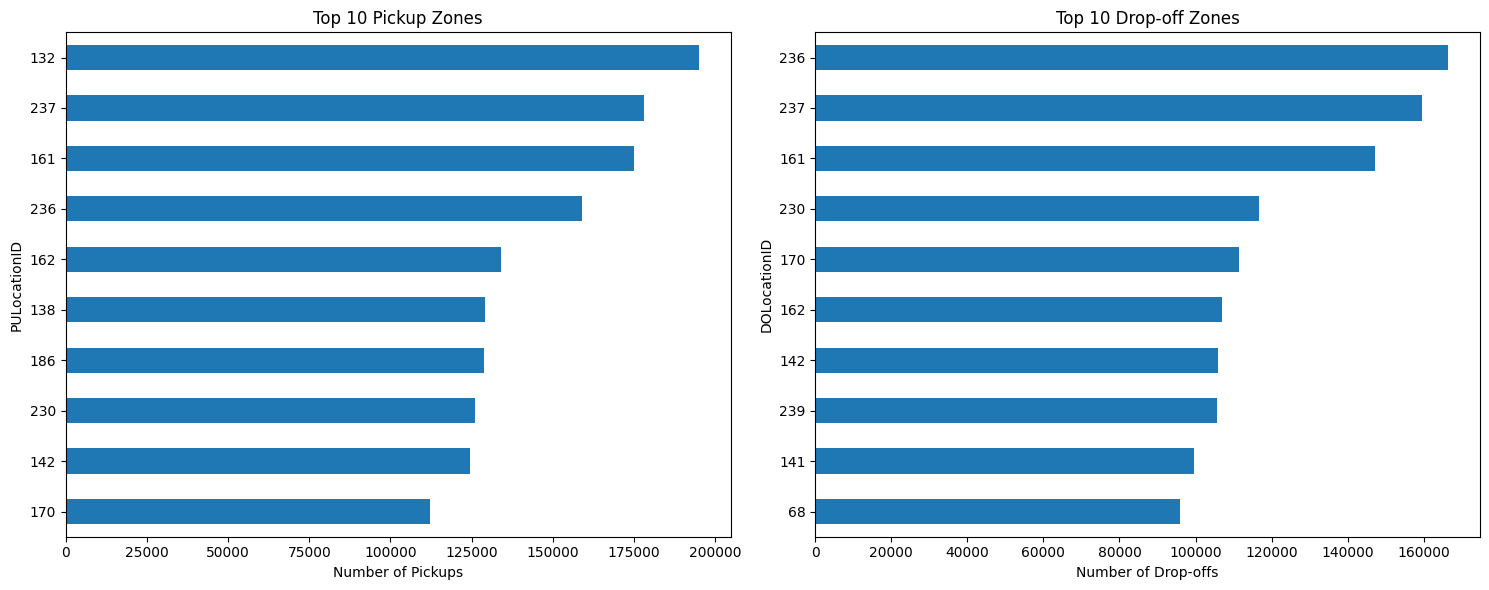

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Top 10 pickup zones
top_10_pickup_zones.sort_values().plot(
    kind='barh',
    ax=axes[0]
)

axes[0].set_title('Top 10 Pickup Zones')
axes[0].set_xlabel('Number of Pickups')
axes[0].set_ylabel('PULocationID')

# Top 10 drop-off zones
top_10_dropoff_zones.sort_values().plot(
    kind='barh',
    ax=axes[1]
)

axes[1].set_title('Top 10 Drop-off Zones')
axes[1].set_xlabel('Number of Drop-offs')
axes[1].set_ylabel('DOLocationID')

plt.tight_layout()
plt.show()

3.2.6 — Find the ratio of pickups and drop-offs in each zone

Step 1 — Create pickup and drop-off counts

In [ ]:
pickup_counts = df['PULocationID'].value_counts()
dropoff_counts = df['DOLocationID'].value_counts()

Step 2 — Combine them into one DataFrame

In [ ]:
zone_traffic = pd.DataFrame({
    'pickups': pickup_counts,
    'dropoffs': dropoff_counts
})

zone_traffic = zone_traffic.fillna(0)

print(zone_traffic.head())

   pickups  dropoffs
1      474   11622.0
2        8      10.0
3       81     298.0
4     4772   14584.0
5       35      55.0


Calculate the ratio

In [ ]:
zone_traffic['pickup_dropoff_ratio'] = (
    zone_traffic['pickups'] /
    zone_traffic['dropoffs'].replace(0, np.nan)
)

print(zone_traffic.head(10))

    pickups  dropoffs  pickup_dropoff_ratio
1       474   11622.0              0.040785
2         8      10.0              0.800000
3        81     298.0              0.271812
4      4772   14584.0              0.327208
5        35      55.0              0.636364
6        38     121.0              0.314050
7      1905   10927.0              0.174339
8        19      63.0              0.301587
9        53     434.0              0.122120
10     1236    3597.0              0.343620


Pickup/Drop-off Ratio

In [ ]:
zone_traffic_filtered = zone_traffic[
    (zone_traffic['pickups'] + zone_traffic['dropoffs']) >= 100
]

top_pickup_ratio = zone_traffic_filtered.sort_values(
    'pickup_dropoff_ratio',
    ascending=False
).head(10)

print("Top 10 zones by pickup/drop-off ratio:")
print(top_pickup_ratio)

Top 10 zones by pickup/drop-off ratio:
     pickups  dropoffs  pickup_dropoff_ratio
70     16896    2249.0              7.512672
132   195086   45946.0              4.245984
138   129204   48911.0              2.641614
186   128863   83055.0              1.551538
114    50646   36434.0              1.390075
43     62624   45864.0              1.365428
249    84040   62937.0              1.335304
162   133999  106893.0              1.253581
100    62595   52041.0              1.202802
161   175056  147181.0              1.189393


In [ ]:
top_dropoff_ratio = zone_traffic_filtered.sort_values(
    'pickup_dropoff_ratio',
    ascending=True
).head(10)

print("Top 10 zones with relatively more drop-offs:")
print(top_dropoff_ratio)

Top 10 zones with relatively more drop-offs:
     pickups  dropoffs  pickup_dropoff_ratio
1        474   11622.0              0.040785
58         5     106.0              0.047170
257      107    1608.0              0.066542
46         8     112.0              0.071429
252       49     685.0              0.071533
96        10     139.0              0.071942
64        34     469.0              0.072495
202      168    2255.0              0.074501
198      161    2083.0              0.077292
200      101    1262.0              0.080032


3.2.7
Identify the top zones with high traffic during night hours

In [ ]:
night_hours = [22, 23, 0, 1, 2, 3, 4, 5]

night_df = df[df['pickup_hour'].isin(night_hours)]

print("Number of night trips:", len(night_df))

Number of night trips: 654905


In [ ]:
df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour

In [ ]:
print(df[['tpep_pickup_datetime', 'pickup_hour']].head())

  tpep_pickup_datetime  pickup_hour
0  2023-09-30 01:39:21            1
1  2023-09-02 04:10:38            4
2  2023-09-11 07:21:33            7
3  2023-09-28 18:24:58           18
4  2023-09-30 23:48:50           23


Filter night hours

In [ ]:
night_hours = [22, 23, 0, 1, 2, 3, 4, 5]

night_df = df[df['pickup_hour'].isin(night_hours)]

print("Number of night trips:", len(night_df))

Number of night trips: 654905


In [ ]:
night_zone_pickups = (
    night_df['PULocationID']
    .value_counts()
)

print("Top 10 zones with highest night-time pickups:")
print(night_zone_pickups.head(10))

Top 10 zones with highest night-time pickups:
PULocationID
132    43184
79     40309
249    33767
48     29122
230    26208
148    23683
114    22930
161    20816
186    20420
142    20157
Name: count, dtype: int64


One small visualization for 3.2.7

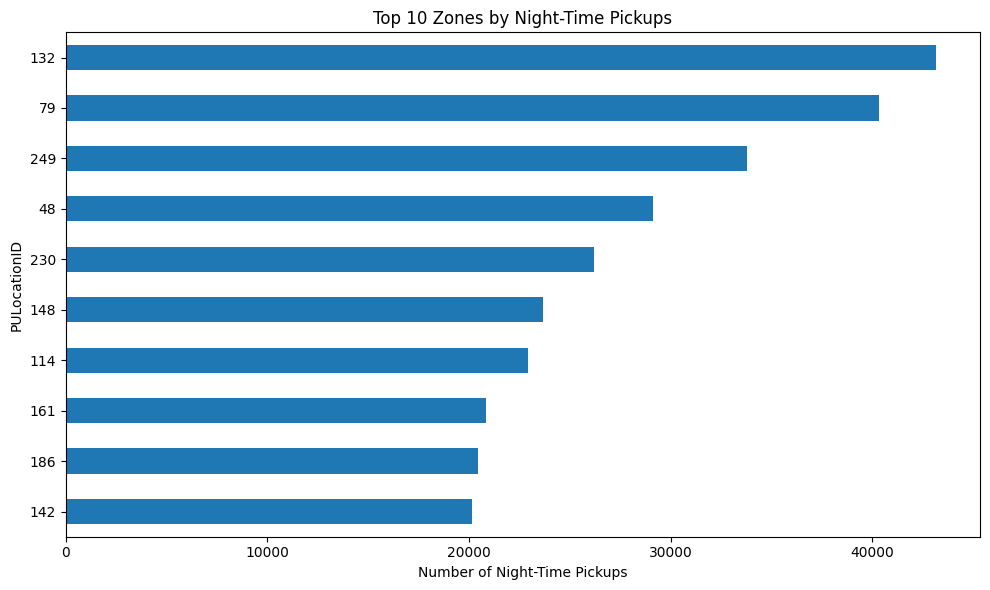

In [ ]:
plt.figure(figsize=(10, 6))

night_zone_pickups.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Zones by Night-Time Pickups')
plt.xlabel('Number of Night-Time Pickups')
plt.ylabel('PULocationID')

plt.tight_layout()
plt.show()

3.2.8 — Revenue share for nighttime vs daytime

Create daytime/nighttime classification

In [ ]:
night_hours = [22, 23, 0, 1, 2, 3, 4, 5]

In [ ]:
df['time_period'] = np.where(
    df['pickup_hour'].isin(night_hours),
    'Night',
    'Day'
)

Calculate revenue for each period

In [ ]:
revenue_by_period = df.groupby('time_period')['total_amount'].sum()

print(revenue_by_period)

time_period
Day      90514281.55
Night    19318091.74
Name: total_amount, dtype: float64


Calculate revenue share

In [ ]:
revenue_share = (
    revenue_by_period / revenue_by_period.sum() * 100
)

print("Revenue Share (%):")
print(revenue_share)

Revenue Share (%):
time_period
Day      82.411295
Night    17.588705
Name: total_amount, dtype: float64


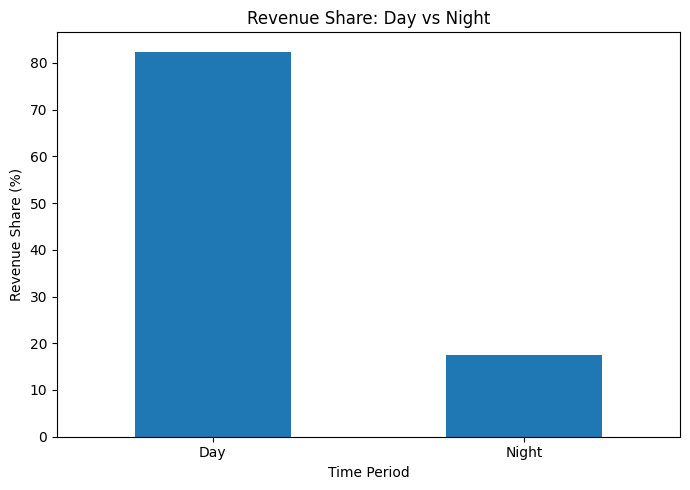

In [ ]:
plt.figure(figsize=(7, 5))

revenue_share.plot(kind='bar', rot=0)

plt.title('Revenue Share: Day vs Night')
plt.xlabel('Time Period')
plt.ylabel('Revenue Share (%)')

plt.tight_layout()
plt.show()

3.2.9 — Average fare per mile per passenger

Create a valid dataset

In [ ]:
fare_per_mile_df = df[
    (df['trip_distance'] > 0) &
    (df['passenger_count'] > 0) &
    (df['fare_amount'] > 0)
].copy()

print("Rows available for analysis:", len(fare_per_mile_df))

Rows available for analysis: 3561718


In [ ]:
fare_per_mile_df['fare_per_mile_per_passenger'] = (
    fare_per_mile_df['fare_amount'] /
    (fare_per_mile_df['trip_distance'] *
     fare_per_mile_df['passenger_count'])
)

In [ ]:
avg_fare_by_passengers = (
    fare_per_mile_df
    .groupby('passenger_count')['fare_per_mile_per_passenger']
    .mean()
)

print(avg_fare_by_passengers)

passenger_count
1.0    10.747191
2.0     6.643478
3.0     4.029738
4.0     4.171222
5.0     1.746951
6.0     1.573288
7.0    21.416702
8.0    64.173901
9.0    81.666667
Name: fare_per_mile_per_passenger, dtype: float64


Check passenger counts

In [ ]:
print(
    fare_per_mile_df['passenger_count']
    .value_counts()
    .sort_index()
)

passenger_count
1.0    2720542
2.0     549946
3.0     136307
4.0      75653
5.0      47769
6.0      31486
7.0          5
8.0          9
9.0          1
Name: count, dtype: int64


Inspect the 7- and 8-passenger trips

In [ ]:
high_passenger_trips = fare_per_mile_df[
    fare_per_mile_df['passenger_count'].isin([7, 8])
][[
    'passenger_count',
    'trip_distance',
    'fare_amount',
    'fare_per_mile_per_passenger'
]].sort_values(
    'fare_per_mile_per_passenger',
    ascending=False
)

print(high_passenger_trips.to_string(index=False))

 passenger_count  trip_distance  fare_amount  fare_per_mile_per_passenger
             8.0           0.04         85.0                   265.625000
             8.0           0.08         87.0                   135.937500
             8.0           0.08         83.0                   129.687500
             7.0           0.13         87.0                    95.604396
             8.0           0.34         60.0                    22.058824
             8.0           0.50         83.0                    20.750000
             7.0           1.25         70.0                     8.000000
             7.0           7.60         70.0                     1.315789
             8.0           8.12         85.0                     1.308498
             7.0           8.15         70.0                     1.226994
             8.0          10.07         82.0                     1.017875
             7.0          10.68         70.0                     0.936330
             8.0          14.88       

Use passenger counts 1–6

In [ ]:
avg_fare_by_passengers_1_6 = (
    fare_per_mile_df[
        fare_per_mile_df['passenger_count'].between(1, 6)
    ]
    .groupby('passenger_count')['fare_per_mile_per_passenger']
    .mean()
)

print("Average fare per mile per passenger:")
print(avg_fare_by_passengers_1_6)

Average fare per mile per passenger:
passenger_count
1.0    10.747191
2.0     6.643478
3.0     4.029738
4.0     4.171222
5.0     1.746951
6.0     1.573288
Name: fare_per_mile_per_passenger, dtype: float64


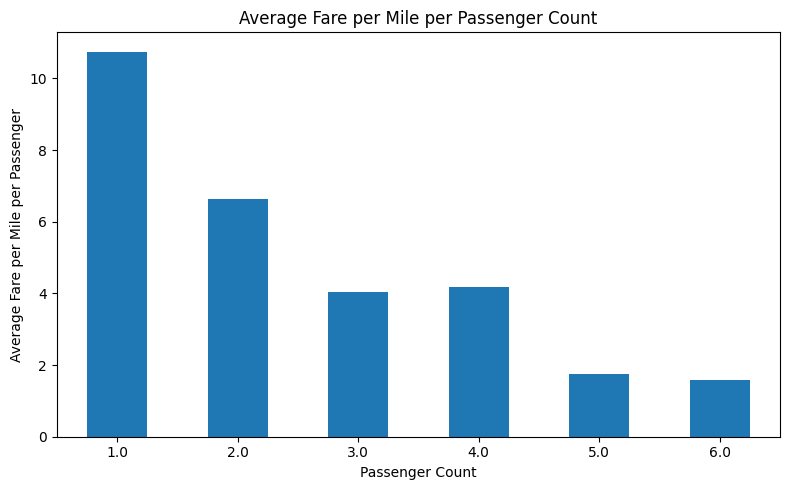

In [ ]:
plt.figure(figsize=(8, 5))

avg_fare_by_passengers_1_6.plot(kind='bar', rot=0)

plt.title('Average Fare per Mile per Passenger Count')
plt.xlabel('Passenger Count')
plt.ylabel('Average Fare per Mile per Passenger')

plt.tight_layout()
plt.show()

3.2.10 — Average fare per mile by hour and day of week

Calculate average fare per mile by hour

In [ ]:
hourly_fare_per_mile = (
    fare_per_mile_df
    .groupby('pickup_hour')
    .apply(lambda x: (x['fare_amount'] / x['trip_distance']).mean())
)

print("Average fare per mile by hour:")
print(hourly_fare_per_mile)

Average fare per mile by hour:
pickup_hour
0     11.491950
1      9.552791
2     11.081286
3     11.222789
4     14.449348
5     15.587334
6      9.723426
7      9.464397
8     11.039096
9     10.439658
10    10.785281
11    11.171325
12    11.640903
13    11.706220
14    12.229753
15    12.423557
16    13.268729
17    12.074486
18    11.105885
19    10.959911
20    10.192555
21    10.250807
22    10.140139
23    11.115804
dtype: float64


/tmp/ipykernel_11829/3639796359.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: (x['fare_amount'] / x['trip_distance']).mean())


hourly visualization

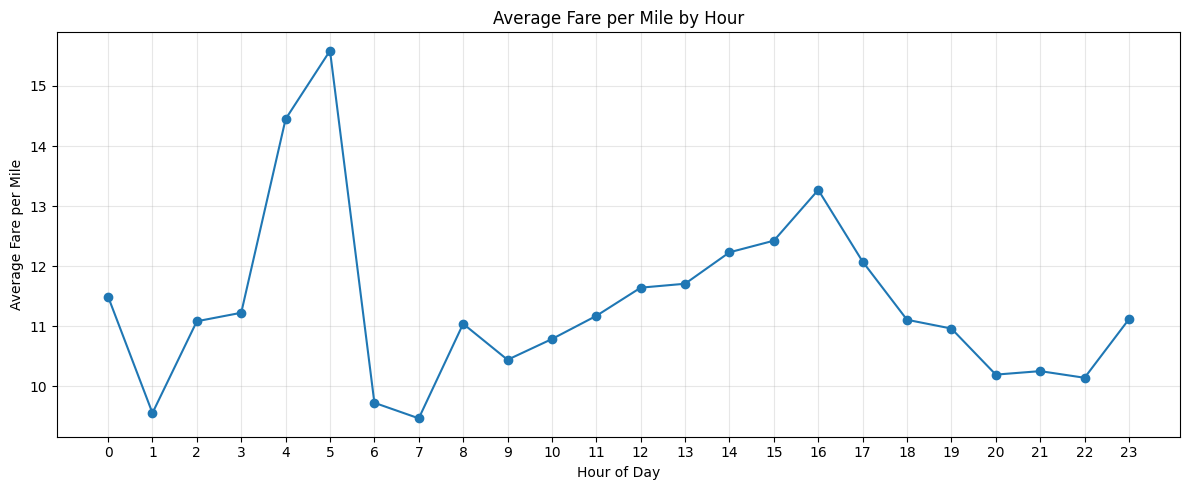

In [ ]:
plt.figure(figsize=(12, 5))

hourly_fare_per_mile.plot(kind='line', marker='o')

plt.title('Average Fare per Mile by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Fare per Mile')

plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Calculate daily average fare per mile

In [ ]:
daily_fare_per_mile = (
    fare_per_mile_df
    .groupby('pickup_day')
    .apply(lambda x: (x['fare_amount'] / x['trip_distance']).mean())
)

print("Average fare per mile by day:")
print(daily_fare_per_mile)

Average fare per mile by day:
pickup_day
Friday       11.157639
Monday       11.096024
Saturday     11.183911
Sunday       11.509304
Thursday     11.276069
Tuesday      11.579690
Wednesday    11.170906
dtype: float64


/tmp/ipykernel_11829/2696491010.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: (x['fare_amount'] / x['trip_distance']).mean())


In [ ]:
fare_per_mile_df = df[
    (df['trip_distance'] > 0) &
    (df['passenger_count'] > 0) &
    (df['fare_amount'] > 0)
].copy()

Create pickup_day

In [ ]:
fare_per_mile_df['pickup_day'] = (
    fare_per_mile_df['tpep_pickup_datetime'].dt.day_name()
)

print(fare_per_mile_df[['tpep_pickup_datetime', 'pickup_day']].head())

  tpep_pickup_datetime pickup_day
0  2023-09-30 01:39:21   Saturday
1  2023-09-02 04:10:38   Saturday
2  2023-09-11 07:21:33     Monday
3  2023-09-28 18:24:58   Thursday
4  2023-09-30 23:48:50   Saturday


In [ ]:
daily_fare_per_mile = (
    fare_per_mile_df
    .groupby('pickup_day')
    .apply(lambda x: (x['fare_amount'] / x['trip_distance']).mean())
)

print(daily_fare_per_mile)

pickup_day
Friday       11.157639
Monday       11.096024
Saturday     11.183911
Sunday       11.509304
Thursday     11.276069
Tuesday      11.579690
Wednesday    11.170906
dtype: float64


/tmp/ipykernel_11829/2041456726.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: (x['fare_amount'] / x['trip_distance']).mean())


Arrange the days correctly

In [ ]:
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_fare_per_mile = daily_fare_per_mile.reindex(day_order)

print(daily_fare_per_mile)

pickup_day
Monday       11.096024
Tuesday      11.579690
Wednesday    11.170906
Thursday     11.276069
Friday       11.157639
Saturday     11.183911
Sunday       11.509304
dtype: float64


final day-of-week chart

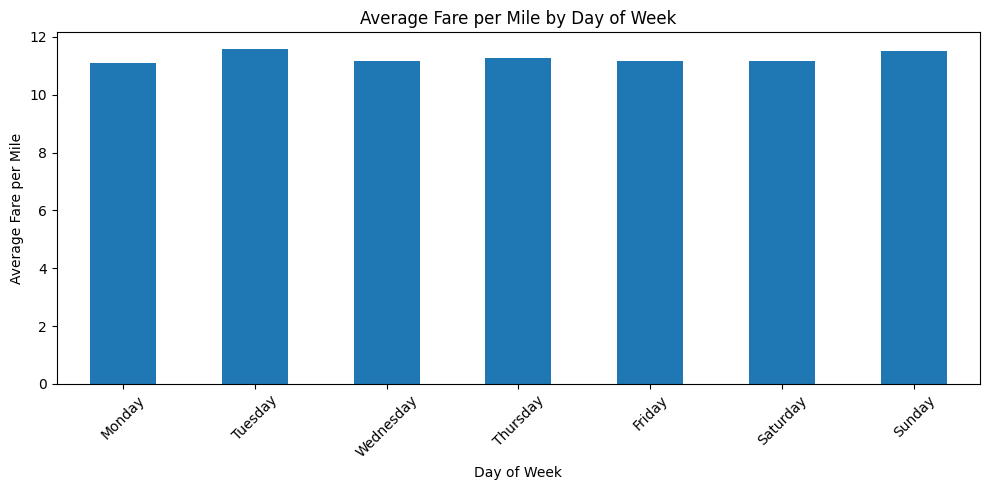

In [ ]:
plt.figure(figsize=(10, 5))

daily_fare_per_mile.plot(kind='bar', rot=45)

plt.title('Average Fare per Mile by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Fare per Mile')

plt.tight_layout()
plt.show()

3.2.11 — Vendor Analysis

Check the vendors

In [ ]:
print(fare_per_mile_df['VendorID'].value_counts())

VendorID
2    2680813
1     880905
Name: count, dtype: int64


Calculate vendor-wise average fare per mile

In [ ]:
vendor_fare_per_mile = (
    fare_per_mile_df
    .groupby('VendorID')
    .apply(lambda x: (x['fare_amount'] / x['trip_distance']).mean())
)

print("Average Fare per Mile by Vendor:")
print(vendor_fare_per_mile)

Average Fare per Mile by Vendor:
VendorID
1     8.125710
2    12.316412
dtype: float64


/tmp/ipykernel_11829/3677379558.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: (x['fare_amount'] / x['trip_distance']).mean())


the vendor chart

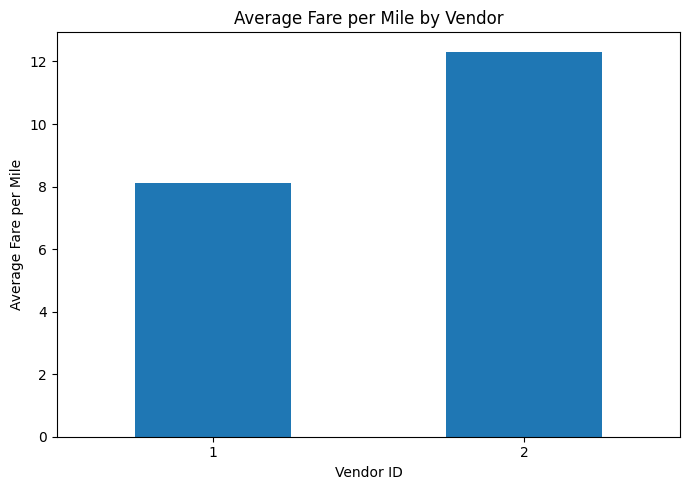

In [ ]:
plt.figure(figsize=(7, 5))

vendor_fare_per_mile.plot(kind='bar', rot=0)

plt.title('Average Fare per Mile by Vendor')
plt.xlabel('Vendor ID')
plt.ylabel('Average Fare per Mile')

plt.tight_layout()
plt.show()

3.2.12 — Vendor Fare Rates by Distance Tier

Create the correct distance tiers

In [ ]:
distance_bins = [0, 2, 5, float('inf')]

distance_labels = [
    'Up to 2 miles',
    '2 to 5 miles',
    'More than 5 miles'
]

fare_per_mile_df['distance_tier'] = pd.cut(
    fare_per_mile_df['trip_distance'],
    bins=distance_bins,
    labels=distance_labels,
    include_lowest=True
)

print(fare_per_mile_df['distance_tier'].value_counts().sort_index())

distance_tier
Up to 2 miles        1975228
2 to 5 miles          968003
More than 5 miles     618487
Name: count, dtype: int64


Calculate average fare per mile by vendor and distance tier

In [ ]:
vendor_distance_fare = (
    fare_per_mile_df
    .groupby(['distance_tier', 'VendorID'], observed=True)
    .apply(lambda x: (x['fare_amount'] / x['trip_distance']).mean())
)

print("Average Fare per Mile by Vendor and Distance Tier:")
print(vendor_distance_fare)

Average Fare per Mile by Vendor and Distance Tier:
distance_tier      VendorID
Up to 2 miles      1            9.944328
                   2           17.758166
2 to 5 miles       1            6.384476
                   2            6.550335
More than 5 miles  1            4.419282
                   2            4.502833
dtype: float64


/tmp/ipykernel_11829/3645156033.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: (x['fare_amount'] / x['trip_distance']).mean())


Create the required visualization

In [ ]:
vendor_distance_fare_df = vendor_distance_fare.unstack()

print(vendor_distance_fare_df)

VendorID                  1          2
distance_tier                         
Up to 2 miles      9.944328  17.758166
2 to 5 miles       6.384476   6.550335
More than 5 miles  4.419282   4.502833


<Figure size 1000x600 with 0 Axes>

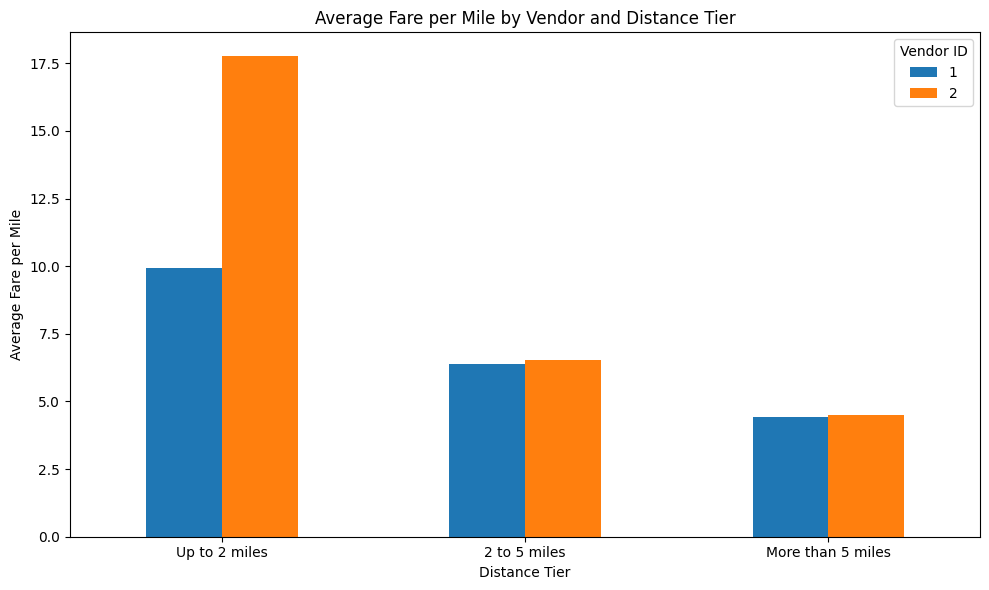

In [ ]:
plt.figure(figsize=(10, 6))

vendor_distance_fare_df.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Average Fare per Mile by Vendor and Distance Tier')
plt.xlabel('Distance Tier')
plt.ylabel('Average Fare per Mile')
plt.xticks(rotation=0)
plt.legend(title='Vendor ID')

plt.tight_layout()
plt.show()

3.2.13 — Analyse the Tip Percentages

In [ ]:
tip_analysis_df = fare_per_mile_df[
    fare_per_mile_df['fare_amount'] > 0
].copy()

tip_analysis_df['tip_percentage'] = (
    tip_analysis_df['tip_amount'] /
    tip_analysis_df['fare_amount']
) * 100

print(tip_analysis_df['tip_percentage'].describe())

count    3.561718e+06
mean     2.054157e+01
std      2.391099e+02
min      0.000000e+00
25%      8.771930e+00
50%      2.404040e+01
75%      2.916667e+01
max      4.500000e+05
Name: tip_percentage, dtype: float64


Check the tip-percentage outliers

In [ ]:
Q1 = tip_analysis_df['tip_percentage'].quantile(0.25)
Q3 = tip_analysis_df['tip_percentage'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 8.771929824561402
Q3: 29.166666666666668
IQR: 20.394736842105267
Lower bound: -21.8201754385965
Upper bound: 59.75877192982457


Count the outliers

In [ ]:
tip_outliers = tip_analysis_df[
    tip_analysis_df['tip_percentage'] > upper_bound
]

print("Number of tip percentage outliers:", len(tip_outliers))

print(
    "Percentage of tip percentage outliers:",
    len(tip_outliers) / len(tip_analysis_df) * 100
)

Number of tip percentage outliers: 14718
Percentage of tip percentage outliers: 0.4132275491771106


Create the cleaned tip dataset

In [ ]:
tip_clean_df = tip_analysis_df[
    tip_analysis_df['tip_percentage'] <= upper_bound
].copy()

print("Rows after removing tip percentage outliers:", len(tip_clean_df))

print(tip_clean_df['tip_percentage'].describe())

Rows after removing tip percentage outliers: 3547000
count    3.547000e+06
mean     2.005971e+01
std      1.321612e+01
min      0.000000e+00
25%      8.571429e+00
50%      2.401235e+01
75%      2.906977e+01
max      5.975610e+01
Name: tip_percentage, dtype: float64


Analyse tip percentage by passenger count

In [ ]:
tip_by_passengers = (
    tip_clean_df
    .groupby('passenger_count')['tip_percentage']
    .mean()
)

print("Average Tip Percentage by Passenger Count:")
print(tip_by_passengers)

Average Tip Percentage by Passenger Count:
passenger_count
1.0    20.319983
2.0    19.476493
3.0    18.772409
4.0    17.038280
5.0    20.307387
6.0    20.226919
7.0    18.710016
8.0    16.933459
9.0    20.837258
Name: tip_percentage, dtype: float64


Create the passenger-count chart


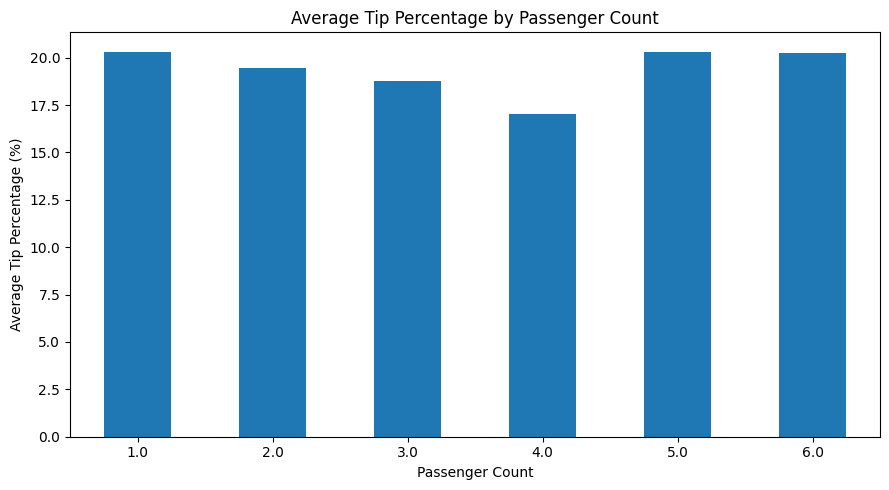

In [ ]:
tip_by_passengers_main = tip_by_passengers.loc[1.0:6.0]

plt.figure(figsize=(9, 5))

tip_by_passengers_main.plot(kind='bar', rot=0)

plt.title('Average Tip Percentage by Passenger Count')
plt.xlabel('Passenger Count')
plt.ylabel('Average Tip Percentage (%)')

plt.tight_layout()
plt.show()


Analyse tip percentage by hour

In [ ]:
tip_by_hour = (
    tip_clean_df
    .groupby('pickup_hour')['tip_percentage']
    .mean()
)

print("Average Tip Percentage by Hour:")
print(tip_by_hour)

Average Tip Percentage by Hour:
pickup_hour
0     20.008455
1     20.189349
2     19.833418
3     19.177711
4     17.204213
5     17.102847
6     17.846413
7     19.403538
8     19.831077
9     19.425980
10    19.019715
11    18.941002
12    18.823613
13    18.705672
14    18.758704
15    18.783430
16    20.476410
17    21.236231
18    21.870869
19    21.815459
20    21.199849
21    21.260939
22    20.890163
23    20.305173
Name: tip_percentage, dtype: float64


Analyse tip percentage by day of week

In [ ]:
tip_by_day = (
    tip_clean_df
    .groupby('pickup_day')['tip_percentage']
    .mean()
)

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

tip_by_day = tip_by_day.reindex(day_order)

print("Average Tip Percentage by Day:")
print(tip_by_day)


Average Tip Percentage by Day:
pickup_day
Monday       20.050282
Tuesday      20.393667
Wednesday    20.537369
Thursday     20.421070
Friday       20.148065
Saturday     19.393751
Sunday       19.309006
Name: tip_percentage, dtype: float64


3.2.14 — Variation of Passenger Count Across Hours and Days

Passenger count by hour

In [ ]:
passenger_by_hour = (
    merged_df
    .groupby('pickup_hour')['passenger_count']
    .mean()
)

print("Average Passenger Count by Hour:")
print(passenger_by_hour)

NameError: name 'merged_df' is not defined

In [ ]:
print([name for name in globals() if isinstance(globals()[name], pd.DataFrame)])

['_', 'df', '_11', 'data', 'sample', '_16', '_25', '_32', 'df_nonzero', 'fare_per_mile_df', 'high_passenger_trips', 'vendor_distance_fare_df', 'tip_analysis_df', 'tip_outliers', 'tip_clean_df']


In [ ]:
print(fare_per_mile_df.shape)
print(fare_per_mile_df.columns.tolist())

(3561718, 25)
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'airport_fee', 'pickup_hour', 'pickup_day', 'pickup_day_num', 'pickup_month', 'distance_tier']


Average passenger count by hour

In [ ]:
passenger_by_hour = (
    fare_per_mile_df
    .groupby('pickup_hour')['passenger_count']
    .mean()
)

print("Average Passenger Count by Hour:")
print(passenger_by_hour)

Average Passenger Count by Hour:
pickup_hour
0     1.433273
1     1.436587
2     1.459763
3     1.453085
4     1.416931
5     1.287646
6     1.261845
7     1.286692
8     1.302241
9     1.321338
10    1.356851
11    1.378098
12    1.389703
13    1.399119
14    1.406669
15    1.414176
16    1.411839
17    1.399739
18    1.387417
19    1.397579
20    1.408651
21    1.427684
22    1.430453
23    1.430839
Name: passenger_count, dtype: float64


Passenger count by day of week

In [ ]:
passenger_by_day = (
    fare_per_mile_df
    .groupby('pickup_day')['passenger_count']
    .mean()
)

day_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

passenger_by_day = passenger_by_day.reindex(day_order)

print("Average Passenger Count by Day:")
print(passenger_by_day)

Average Passenger Count by Day:
pickup_day
Monday       1.366539
Tuesday      1.337750
Wednesday    1.338593
Thursday     1.349049
Friday       1.407207
Saturday     1.489505
Sunday       1.473321
Name: passenger_count, dtype: float64


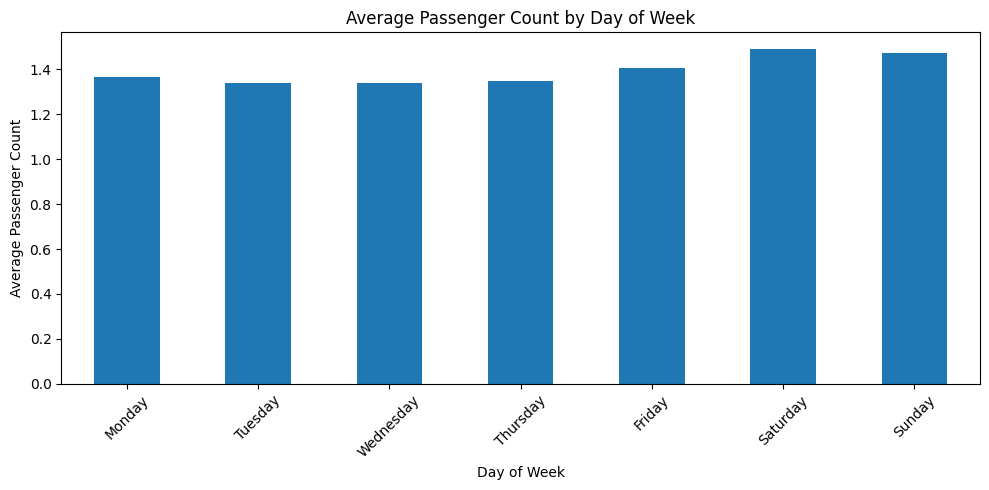

In [ ]:
plt.figure(figsize=(10, 5))

passenger_by_day.plot(kind='bar', rot=45)

plt.title('Average Passenger Count by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Passenger Count')

plt.tight_layout()
plt.show()

3.2.15 — Passenger Count Across Pickup Zones

Average passenger count by pickup zone

In [ ]:
passenger_by_pickup_zone = (
    fare_per_mile_df
    .groupby('PULocationID')['passenger_count']
    .mean()
    .sort_values(ascending=False)
)

print("Top 10 Pickup Zones by Average Passenger Count:")
print(passenger_by_pickup_zone.head(10))

Top 10 Pickup Zones by Average Passenger Count:
PULocationID
221    2.500000
115    2.000000
6      1.885714
12     1.840625
195    1.758209
66     1.651914
2      1.625000
240    1.600000
59     1.600000
93     1.566529
Name: passenger_count, dtype: float64


In [ ]:
print("\nBottom 10 Pickup Zones by Average Passenger Count:")
print(passenger_by_pickup_zone.tail(10))


Bottom 10 Pickup Zones by Average Passenger Count:
PULocationID
149    1.0
156    1.0
222    1.0
214    1.0
201    1.0
206    1.0
199    1.0
23     1.0
30     1.0
245    1.0
Name: passenger_count, dtype: float64


Check the number of trips in each zone

In [ ]:
zone_passenger_stats = (
    fare_per_mile_df
    .groupby('PULocationID')
    .agg(
        avg_passenger_count=('passenger_count', 'mean'),
        trip_count=('passenger_count', 'size')
    )
)

print("Top 10 zones by average passenger count:")
print(
    zone_passenger_stats
    .sort_values('avg_passenger_count', ascending=False)
    .head(10)
)

print("\nBottom 10 zones by average passenger count:")
print(
    zone_passenger_stats
    .sort_values('avg_passenger_count')
    .head(10)
)

Top 10 zones by average passenger count:
              avg_passenger_count  trip_count
PULocationID                                 
221                      2.500000           2
115                      2.000000           1
6                        1.885714          35
12                       1.840625        1600
195                      1.758209         335
66                       1.651914         836
2                        1.625000           8
240                      1.600000          10
59                       1.600000           5
93                       1.566529         729

Bottom 10 zones by average passenger count:
              avg_passenger_count  trip_count
PULocationID                                 
23                            1.0          47
30                            1.0           2
245                           1.0           1
46                            1.0           7
44                            1.0          18
58                            1.0       

Filter low-volume zones

In [ ]:
# Keep only pickup zones with at least 100 trips
reliable_zone_stats = zone_passenger_stats[
    zone_passenger_stats['trip_count'] >= 100
]

print("Number of reliable pickup zones:")
print(len(reliable_zone_stats))

print("\nTop 10 reliable pickup zones by average passenger count:")
print(
    reliable_zone_stats
    .sort_values('avg_passenger_count', ascending=False)
    .head(10)
)

Number of reliable pickup zones:
167

Top 10 reliable pickup zones by average passenger count:
              avg_passenger_count  trip_count
PULocationID                                 
12                       1.840625        1600
195                      1.758209         335
66                       1.651914         836
93                       1.566529         729
45                       1.553932        4654
261                      1.549612       18282
194                      1.525547         137
88                       1.515007        9629
230                      1.513055      120527
43                       1.510359       59995


In [ ]:
print("\nBottom 10 reliable pickup zones by average passenger count:")
print(
    reliable_zone_stats
    .sort_values('avg_passenger_count')
    .head(10)
)


Bottom 10 reliable pickup zones by average passenger count:
              avg_passenger_count  trip_count
PULocationID                                 
121                      1.000000         154
222                      1.000000         153
191                      1.004975         201
210                      1.008264         121
77                       1.009091         110
205                      1.010274         292
35                       1.014337         279
182                      1.014388         139
254                      1.014925         201
218                      1.015267         262


Create the visualization

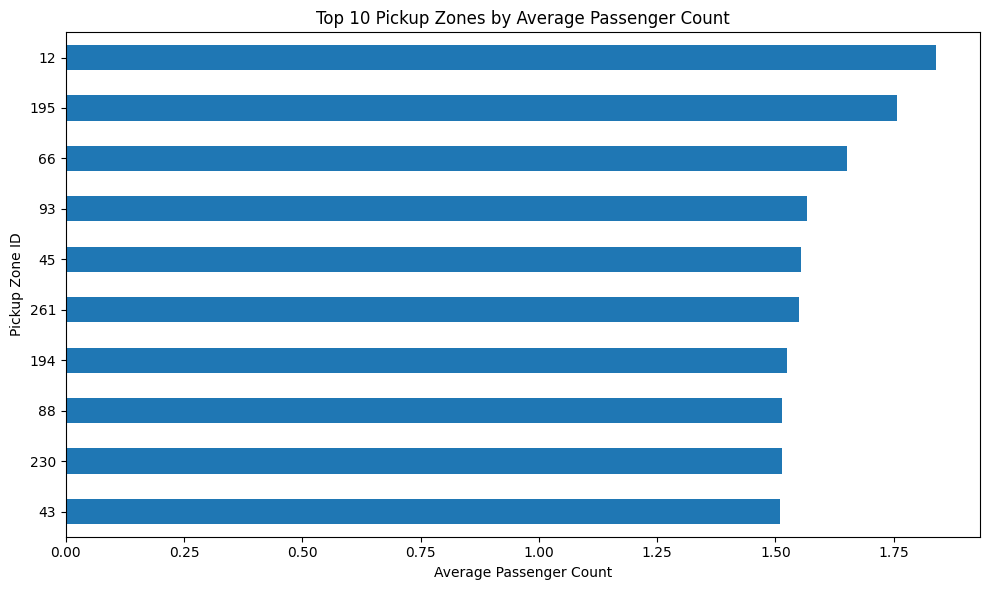

In [ ]:
top_reliable_zones = (
    reliable_zone_stats
    .sort_values('avg_passenger_count', ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

top_reliable_zones['avg_passenger_count'].sort_values().plot(
    kind='barh'
)

plt.title('Top 10 Pickup Zones by Average Passenger Count')
plt.xlabel('Average Passenger Count')
plt.ylabel('Pickup Zone ID')

plt.tight_layout()
plt.show()

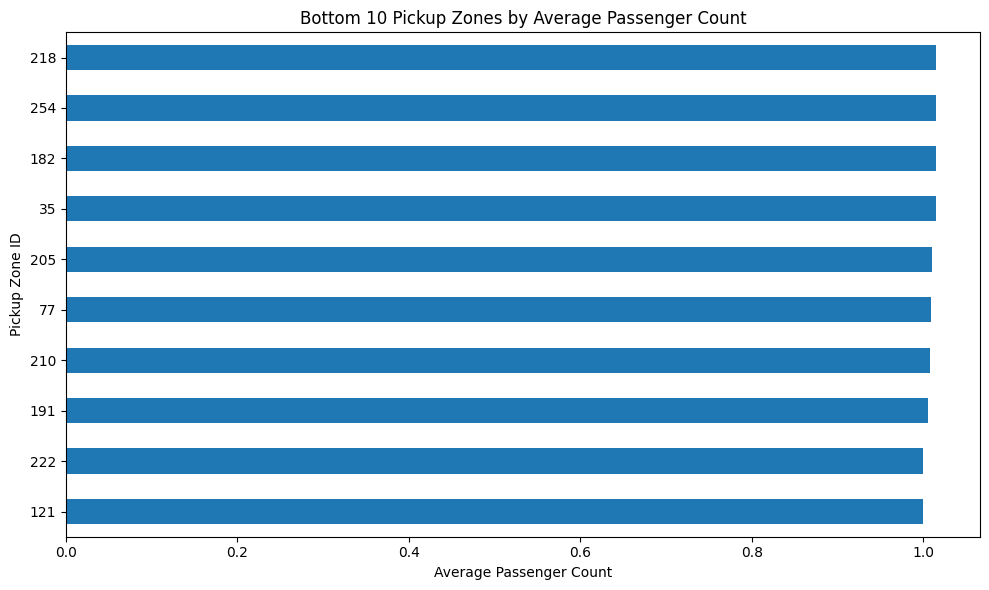

In [ ]:
bottom_reliable_zones = (
    reliable_zone_stats
    .sort_values('avg_passenger_count')
    .head(10)
)

plt.figure(figsize=(10, 6))

bottom_reliable_zones['avg_passenger_count'].sort_values().plot(
    kind='barh'
)

plt.title('Bottom 10 Pickup Zones by Average Passenger Count')
plt.xlabel('Average Passenger Count')
plt.ylabel('Pickup Zone ID')

plt.tight_layout()
plt.show()

Analyse the pickup/drop-off zones or times when extra charges are applied more frequently.

In [ ]:
print("Extra charge value counts:")
print(fare_per_mile_df['extra'].value_counts().sort_index())

print("\nPercentage of trips with extra charges:")

extra_charge_percentage = (
    (fare_per_mile_df['extra'] > 0).mean() * 100
)

print(extra_charge_percentage)

Extra charge value counts:
extra
0.00     1372250
0.01           2
0.02           4
0.04           2
0.07           1
          ...   
11.75       2456
12.50          1
12.75          4
13.75          1
14.25          3
Name: count, Length: 64, dtype: int64

Percentage of trips with extra charges:
61.472244574107215


In [ ]:
extra_by_hour = (
    fare_per_mile_df
    .groupby('pickup_hour')['extra']
    .apply(lambda x: (x > 0).sum())
)

total_trips_by_hour = (
    fare_per_mile_df
    .groupby('pickup_hour')
    .size()
)

extra_charge_rate_by_hour = (
    extra_by_hour / total_trips_by_hour * 100
)

print("Extra charge rate by hour (%):")
print(extra_charge_rate_by_hour)

Extra charge rate by hour (%):
pickup_hour
0     96.685686
1     97.668367
2     98.381406
3     97.581297
4     91.890838
5     85.013317
6     31.703741
7     28.761184
8     28.692923
9     29.767007
10    29.960003
11    29.080682
12    29.029743
13    29.131992
14    29.501919
15    29.484069
16    75.713661
17    79.619573
18    80.546743
19    79.816737
20    95.504300
21    96.820464
22    96.523972
23    96.193867
dtype: float64


Create the visualization

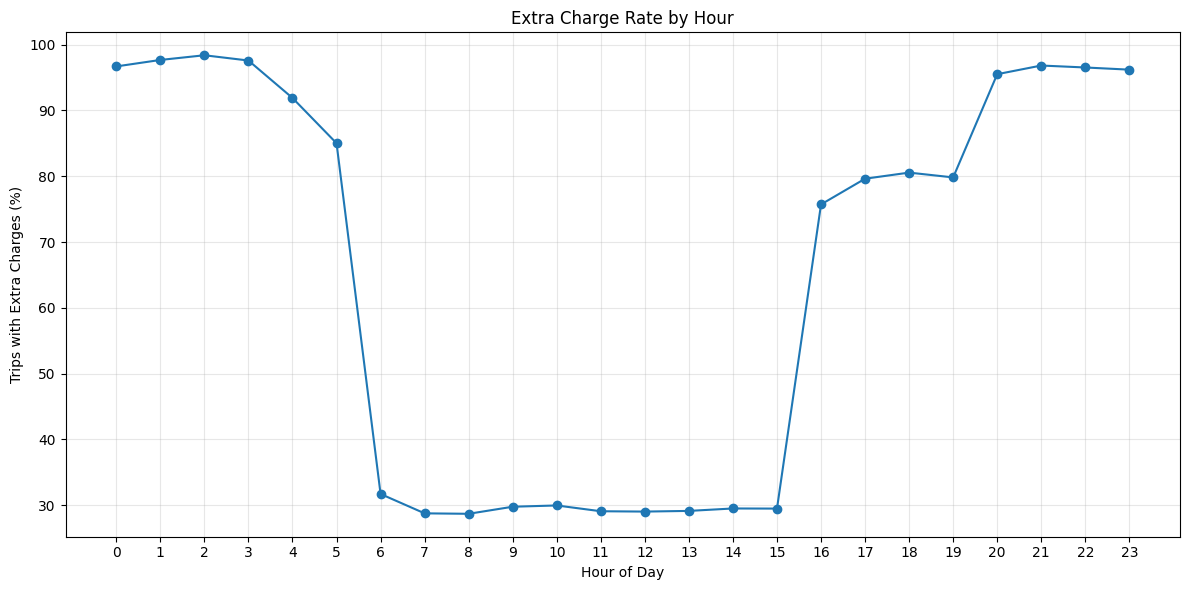

In [ ]:
plt.figure(figsize=(12, 6))

extra_charge_rate_by_hour.plot(
    kind='line',
    marker='o'
)

plt.title('Extra Charge Rate by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Trips with Extra Charges (%)')
plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Extra charges by pickup zone.

In [ ]:
zone_lookup = zones.set_index('LocationID')['zone'].to_dict()

extra_by_pu_zone = (
    fare_per_mile_df
    .groupby('PULocationID')['extra']
    .apply(lambda x: (x > 0).mean() * 100)
)

pu_zone_trip_counts = fare_per_mile_df.groupby('PULocationID').size()

# Keep only zones with a reasonable sample size
extra_by_pu_zone_reliable = extra_by_pu_zone[pu_zone_trip_counts >= 100]

extra_by_pu_zone_df = extra_by_pu_zone_reliable.reset_index()
extra_by_pu_zone_df.columns = ['PULocationID', 'extra_charge_rate']
extra_by_pu_zone_df['zone'] = extra_by_pu_zone_df['PULocationID'].map(zone_lookup)

top_10_extra_zones = extra_by_pu_zone_df.sort_values('extra_charge_rate', ascending=False).head(10)
bottom_10_extra_zones = extra_by_pu_zone_df.sort_values('extra_charge_rate', ascending=True).head(10)

print("Top 10 pickup zones by extra-charge rate:")
print(top_10_extra_zones)
print()
print("Bottom 10 pickup zones by extra-charge rate:")
print(bottom_10_extra_zones)

NameError: name 'zones' is not defined

In [ ]:
import geopandas as gpd

zones = gpd.read_file('/content/drive/MyDrive/Datasets and Dictionary-NYC/Datasets and Dictionary/taxi_zones/taxi_zones.shp')

# Re-apply the dissolve fix for duplicate LocationIDs (56 and 103)
zones = zones.dissolve(by='LocationID', as_index=False, aggfunc={
    'OBJECTID': 'first',
    'Shape_Leng': 'sum',
    'Shape_Area': 'sum',
    'zone': 'first',
    'borough': 'first'
})

print(zones.shape)
print("Duplicate LocationIDs:", zones['LocationID'].duplicated().sum())

(260, 7)
Duplicate LocationIDs: 0


In [ ]:
print(fare_per_mile_df.shape)
print(fare_per_mile_df.columns.tolist())

(3561718, 25)
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'airport_fee', 'pickup_hour', 'pickup_day', 'pickup_day_num', 'pickup_month', 'distance_tier']


Extra charges by pickup zone

In [ ]:
zone_lookup = zones.set_index('LocationID')['zone'].to_dict()

extra_by_pu_zone = (
    fare_per_mile_df
    .groupby('PULocationID')['extra']
    .apply(lambda x: (x > 0).mean() * 100)
)

pu_zone_trip_counts = fare_per_mile_df.groupby('PULocationID').size()

# Keep only zones with a reasonable sample size
extra_by_pu_zone_reliable = extra_by_pu_zone[pu_zone_trip_counts >= 100]

extra_by_pu_zone_df = extra_by_pu_zone_reliable.reset_index()
extra_by_pu_zone_df.columns = ['PULocationID', 'extra_charge_rate']
extra_by_pu_zone_df['zone'] = extra_by_pu_zone_df['PULocationID'].map(zone_lookup)

top_10_extra_zones = extra_by_pu_zone_df.sort_values('extra_charge_rate', ascending=False).head(10)
bottom_10_extra_zones = extra_by_pu_zone_df.sort_values('extra_charge_rate', ascending=True).head(10)

print("Top 10 pickup zones by extra-charge rate:")
print(top_10_extra_zones)
print()
print("Bottom 10 pickup zones by extra-charge rate:")
print(bottom_10_extra_zones)

Top 10 pickup zones by extra-charge rate:
     PULocationID  extra_charge_rate                       zone
81            138          98.787591          LaGuardia Airport
159           255          84.139483  Williamsburg (North Side)
90            148          83.400279            Lower East Side
37             70          83.210559              East Elmhurst
1               4          82.697623              Alphabet City
160           256          79.551122  Williamsburg (South Side)
65            114          79.319010    Greenwich Village South
63            112          77.099237                 Greenpoint
45             79          76.493559               East Village
157           249          74.888768               West Village

Bottom 10 pickup zones by extra-charge rate:
     PULocationID  extra_charge_rate                          zone
69            121           0.649351             Hillcrest/Pomonok
27             51           1.034483                    Co-Op City
38     

Visualize top zones

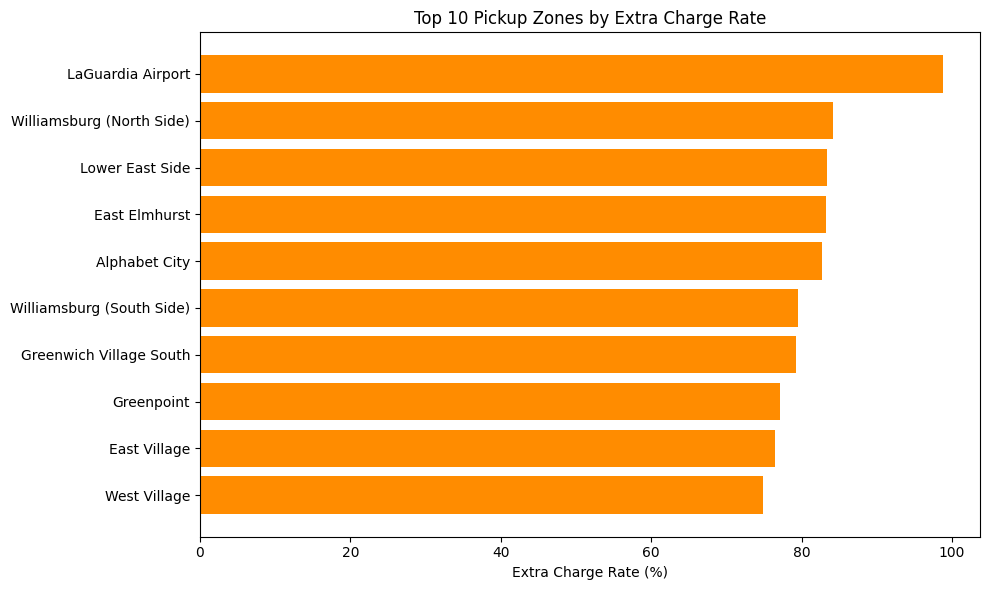

In [ ]:
plt.figure(figsize=(10, 6))
plt.barh(top_10_extra_zones['zone'], top_10_extra_zones['extra_charge_rate'], color='darkorange')
plt.xlabel('Extra Charge Rate (%)')
plt.title('Top 10 Pickup Zones by Extra Charge Rate')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

4.Conclusions

4.1.Final Insights and Recommendations

4.1.1.Recommendations to optimize routing and dispatching based on demand patterns and operational inefficiencies.


In [ ]:
for var in ['merged_df', 'fare_per_mile_df', 'hourly_trips_detailed', 'weekday_avg', 'weekend_avg', 'slowest_routes', 'trips_per_zone', 'zones_with_trips_sorted', 'zones']:
    print(var, ':', 'EXISTS' if var in dir() else 'MISSING')

merged_df : MISSING
fare_per_mile_df : EXISTS
hourly_trips_detailed : MISSING
weekday_avg : MISSING
weekend_avg : MISSING
slowest_routes : MISSING
trips_per_zone : MISSING
zones_with_trips_sorted : MISSING
zones : EXISTS


In [ ]:
print(fare_per_mile_df.columns.tolist())
print(fare_per_mile_df.shape)

['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'airport_fee', 'pickup_hour', 'pickup_day', 'pickup_day_num', 'pickup_month', 'distance_tier']
(3561718, 25)


In [ ]:

# 1. Merge zone names onto fare_per_mile_df
zone_lookup = zones.set_index('LocationID')['zone'].to_dict()
borough_lookup = zones.set_index('LocationID')['borough'].to_dict()

merged_df = fare_per_mile_df.copy()
merged_df['pickup_zone'] = merged_df['PULocationID'].map(zone_lookup)
merged_df['pickup_borough'] = merged_df['PULocationID'].map(borough_lookup)
merged_df['dropoff_zone'] = merged_df['DOLocationID'].map(zone_lookup)

# 2. Trip duration and speed
merged_df['trip_duration_min'] = (
    merged_df['tpep_dropoff_datetime'] - merged_df['tpep_pickup_datetime']
).dt.total_seconds() / 60
merged_df['speed_mph'] = merged_df['trip_distance'] / (merged_df['trip_duration_min'] / 60)

# 3. Hourly trip counts
hourly_trips_detailed = merged_df.groupby('pickup_hour').size()
print("hourly_trips_detailed rebuilt:", hourly_trips_detailed.shape)

# 4. Weekday vs weekend
merged_df['is_weekend'] = merged_df['tpep_pickup_datetime'].dt.dayofweek >= 5
weekday_hourly = merged_df[~merged_df['is_weekend']].groupby('pickup_hour').size()
weekend_hourly = merged_df[merged_df['is_weekend']].groupby('pickup_hour').size()
weekday_avg = weekday_hourly / 5
weekend_avg = weekend_hourly / 2
print("weekday_avg / weekend_avg rebuilt")

# 5. Slowest routes
route_speed = (
    merged_df.groupby(['PULocationID', 'DOLocationID', 'pickup_hour'])['speed_mph']
    .mean()
    .reset_index()
)
route_counts = merged_df.groupby(['PULocationID', 'DOLocationID', 'pickup_hour']).size().reset_index(name='trip_count')
route_speed = route_speed.merge(route_counts, on=['PULocationID', 'DOLocationID', 'pickup_hour'])
route_speed_reliable = route_speed[route_speed['trip_count'] >= 20]

slowest_routes = route_speed_reliable.sort_values('speed_mph').head(15).copy()
slowest_routes['pickup_zone'] = slowest_routes['PULocationID'].map(zone_lookup)
slowest_routes['dropoff_zone'] = slowest_routes['DOLocationID'].map(zone_lookup)
print("slowest_routes rebuilt:", slowest_routes.shape)

# 6. Trips per zone
trips_per_zone = (
    merged_df.groupby(['PULocationID', 'pickup_zone', 'pickup_borough'])
    .size()
    .reset_index(name='trip_count')
    .rename(columns={'pickup_zone': 'zone', 'pickup_borough': 'borough'})
    .sort_values('trip_count', ascending=False)
)
print("trips_per_zone rebuilt:", trips_per_zone.shape)

# 7. Zones with trips, sorted
zones_with_trips = zones.merge(
    trips_per_zone[['PULocationID', 'trip_count']],
    left_on='LocationID', right_on='PULocationID', how='left'
)
zones_with_trips['trip_count'] = zones_with_trips['trip_count'].fillna(0)
zones_with_trips_sorted = zones_with_trips[['zone', 'borough', 'trip_count']].sort_values('trip_count', ascending=False)
print("zones_with_trips_sorted rebuilt:", zones_with_trips_sorted.shape)

print("\nAll variables rebuilt successfully.")

hourly_trips_detailed rebuilt: (24,)
weekday_avg / weekend_avg rebuilt
slowest_routes rebuilt: (15, 7)
trips_per_zone rebuilt: (253, 4)
zones_with_trips_sorted rebuilt: (260, 3)

All variables rebuilt successfully.


In [ ]:
# ============================================
# 4.1.1 — Supporting analysis for routing/dispatch recommendations
# ============================================

# 1. Evening surge ramp-up: hourly trip volumes leading into peak
ramp_up_hours = hourly_trips_detailed.loc[14:19]
print("Trip volume ramp-up (2 PM - 7 PM):")
print(ramp_up_hours)
print()

# 2. Slowest gridlock routes recap
print("Top 5 slowest routes (with zone names):")
print(slowest_routes[['pickup_zone', 'dropoff_zone', 'pickup_hour', 'speed_mph', 'trip_count']].head(5))
print()

# 3. Weekday vs weekend peak comparison
weekday_peak_hour = weekday_avg.idxmax()
weekday_peak_val = weekday_avg.max()
weekend_peak_hour = weekend_avg.idxmax()
weekend_peak_val = weekend_avg.max()

print(f"Weekday peak hour: {weekday_peak_hour}:00 ({weekday_peak_val:.0f} avg trips)")
print(f"Weekend peak hour: {weekend_peak_hour}:00 ({weekend_peak_val:.0f} avg trips)")
print()

# 4. Airport trip volume (JFK + LaGuardia combined)
airport_zones = trips_per_zone[trips_per_zone['zone'].isin(['JFK Airport', 'LaGuardia Airport'])]
total_airport_trips = airport_zones['trip_count'].sum()
print("Airport zone trip volumes:")
print(airport_zones[['zone', 'trip_count']])
print(f"Combined airport trips: {total_airport_trips}")
print()

# 5. Lowest-demand zones (near-zero trips)
low_demand_zones = zones_with_trips_sorted[zones_with_trips_sorted['trip_count'] <= 1]
print(f"Number of zones with 0-1 trips: {len(low_demand_zones)}")
print(low_demand_zones[['zone', 'borough', 'trip_count']])

Trip volume ramp-up (2 PM - 7 PM):
pickup_hour
14    216230
15    222181
16    221919
17    241045
18    252477
19    226232
dtype: int64

Top 5 slowest routes (with zone names):
                         pickup_zone                  dropoff_zone  \
61271                    JFK Airport                  East Chelsea   
111087  Penn Station/Madison Sq West              Garment District   
111088  Penn Station/Madison Sq West              Garment District   
111086  Penn Station/Madison Sq West              Garment District   
112096  Penn Station/Madison Sq West  Penn Station/Madison Sq West   

        pickup_hour  speed_mph  trip_count  
61271            16 -57.696233         282  
111087           12   3.557032         179  
111088           13   3.581721         156  
111086           11   3.827310         159  
112096           13   3.851758          63  

Weekday peak hour: 18:00 (38492 avg trips)
Weekend peak hour: 17:00 (30291 avg trips)

Airport zone trip volumes:
               

Check for negative distance/duration in merged_df

In [ ]:
print("Negative trip_distance:", (merged_df['trip_distance'] < 0).sum())
print("Negative trip_duration_min:", (merged_df['trip_duration_min'] < 0).sum())
print("Zero or negative duration:", (merged_df['trip_duration_min'] <= 0).sum())

Negative trip_distance: 0
Negative trip_duration_min: 78
Zero or negative duration: 140


In [ ]:
merged_df_clean = merged_df[
    (merged_df['trip_distance'] > 0) &
    (merged_df['trip_duration_min'] > 0) &
    (merged_df['trip_duration_min'] <= 180)
].copy()

merged_df_clean['speed_mph'] = merged_df_clean['trip_distance'] / (merged_df_clean['trip_duration_min'] / 60)

route_speed = (
    merged_df_clean.groupby(['PULocationID', 'DOLocationID', 'pickup_hour'])['speed_mph']
    .mean()
    .reset_index()
)
route_counts = merged_df_clean.groupby(['PULocationID', 'DOLocationID', 'pickup_hour']).size().reset_index(name='trip_count')
route_speed = route_speed.merge(route_counts, on=['PULocationID', 'DOLocationID', 'pickup_hour'])
route_speed_reliable = route_speed[route_speed['trip_count'] >= 20]

slowest_routes = route_speed_reliable.sort_values('speed_mph').head(15).copy()
slowest_routes['pickup_zone'] = slowest_routes['PULocationID'].map(zone_lookup)
slowest_routes['dropoff_zone'] = slowest_routes['DOLocationID'].map(zone_lookup)

print(slowest_routes[['pickup_zone', 'dropoff_zone', 'pickup_hour', 'speed_mph', 'trip_count']])

                         pickup_zone                  dropoff_zone  \
110985  Penn Station/Madison Sq West              Garment District   
110986  Penn Station/Madison Sq West              Garment District   
110984  Penn Station/Madison Sq West              Garment District   
111993  Penn Station/Madison Sq West  Penn Station/Madison Sq West   
83158            Little Italy/NoLiTa           Little Italy/NoLiTa   
110989  Penn Station/Madison Sq West              Garment District   
83157            Little Italy/NoLiTa           Little Italy/NoLiTa   
112465  Penn Station/Madison Sq West     Times Sq/Theatre District   
112466  Penn Station/Madison Sq West     Times Sq/Theatre District   
110988  Penn Station/Madison Sq West              Garment District   
95024                 Midtown Center     Times Sq/Theatre District   
105913                   Murray Hill                  Clinton East   
110983  Penn Station/Madison Sq West              Garment District   
97811               

4.1.2 — Supporting analysis for zone positioning recommendations

In [ ]:


# Top 10 busiest zones and their % share of total trips
total_trips = trips_per_zone['trip_count'].sum()
top_10_zones = trips_per_zone.head(10).copy()
top_10_zones['pct_of_total'] = (top_10_zones['trip_count'] / total_trips * 100).round(2)
print("Top 10 busiest zones:")
print(top_10_zones[['zone', 'borough', 'trip_count', 'pct_of_total']])

# How many of the top 10 are in Manhattan
manhattan_count = (top_10_zones['borough'] == 'Manhattan').sum()
print(f"\nManhattan zones in top 10: {manhattan_count}/10")

# Airport share of total demand
print(f"Airport trips (JFK + LaGuardia): {total_airport_trips} ({(total_airport_trips/total_trips*100):.2f}% of all trips)")

# Zones with almost no demand
print(f"\nZones with 0-1 trips: {len(low_demand_zones)} out of {len(zones_with_trips_sorted)} total zones")

Top 10 busiest zones:
                             zone    borough  trip_count  pct_of_total
124                   JFK Airport     Queens      188804          5.35
226         Upper East Side South  Manhattan      170761          4.84
153                Midtown Center  Manhattan      167749          4.75
225         Upper East Side North  Manhattan      150369          4.26
154                  Midtown East  Manhattan      128975          3.65
130             LaGuardia Airport     Queens      126360          3.58
177  Penn Station/Madison Sq West  Manhattan      124177          3.52
219     Times Sq/Theatre District  Manhattan      120527          3.41
134           Lincoln Square East  Manhattan      117993          3.34
162                   Murray Hill  Manhattan      106711          3.02

Manhattan zones in top 10: 8/10
Airport trips (JFK + LaGuardia): 315164 (8.93% of all trips)

Zones with 0-1 trips: 12 out of 260 total zones


4.1.3 — Pricing strategy supporting numbers


In [ ]:

# 1. Confirm fare/distance/duration/passenger correlations (recap from 3.1.7)
print("Fare vs Distance correlation:", merged_df_clean['fare_amount'].corr(merged_df_clean['trip_distance']))
print("Fare vs Duration correlation:", merged_df_clean['fare_amount'].corr(merged_df_clean['trip_duration_min']))
print("Fare vs Passenger correlation:", merged_df_clean['fare_amount'].corr(merged_df_clean['passenger_count']))
print()

# 2. Average fare per mile by distance tier (uses your existing distance_tier column)
fare_by_tier = fare_per_mile_df.groupby('distance_tier').apply(
    lambda x: (x['fare_amount'] / x['trip_distance']).mean()
)
print("Average fare per mile by distance tier:")
print(fare_by_tier)
print()

# 3. Average fare per mile by vendor
fare_by_vendor = fare_per_mile_df.groupby('VendorID').apply(
    lambda x: (x['fare_amount'] / x['trip_distance']).mean()
)
print("Average fare per mile by vendor:")
print(fare_by_vendor)
print()

# 4. Extra charge rate: 4-6 PM vs 8PM+ comparison
rush_rate = extra_charge_rate_by_hour.loc[[16, 17, 18]].mean()
night_rate = extra_charge_rate_by_hour.loc[[20, 21, 22, 23]].mean()
print(f"Avg extra-charge rate 4-6 PM: {rush_rate:.2f}%")
print(f"Avg extra-charge rate 8PM+: {night_rate:.2f}%")

Fare vs Distance correlation: 0.06299138704645629
Fare vs Duration correlation: 0.843298995102334
Fare vs Passenger correlation: 0.04199451874403013



/tmp/ipykernel_11829/474880269.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fare_by_tier = fare_per_mile_df.groupby('distance_tier').apply(
/tmp/ipykernel_11829/474880269.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fare_by_tier = fare_per_mile_df.groupby('distance_tier').apply(


Average fare per mile by distance tier:
distance_tier
Up to 2 miles        15.745206
2 to 5 miles          6.510786
More than 5 miles     4.483753
dtype: float64

Average fare per mile by vendor:
VendorID
1     8.125710
2    12.316412
dtype: float64

Avg extra-charge rate 4-6 PM: 78.63%
Avg extra-charge rate 8PM+: 96.26%


/tmp/ipykernel_11829/474880269.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fare_by_vendor = fare_per_mile_df.groupby('VendorID').apply(


In [ ]:
merged_df_clean2 = merged_df_clean[merged_df_clean['fare_amount'] <= 200].copy()

print("Rows before:", len(merged_df_clean))
print("Rows after capping fare_amount:", len(merged_df_clean2))
print()
print("Fare vs Distance correlation (cleaned):", merged_df_clean2['fare_amount'].corr(merged_df_clean2['trip_distance']))
print("Fare vs Duration correlation (cleaned):", merged_df_clean2['fare_amount'].corr(merged_df_clean2['trip_duration_min']))
print("Fare vs Passenger correlation (cleaned):", merged_df_clean2['fare_amount'].corr(merged_df_clean2['passenger_count']))

Rows before: 3558143
Rows after capping fare_amount: 3557027

Fare vs Distance correlation (cleaned): 0.06087586040672666
Fare vs Duration correlation (cleaned): 0.8561115774987317
Fare vs Passenger correlation (cleaned): 0.04310087453500229


Check trip_distance range in merged_df_clean2

In [ ]:
print(merged_df_clean2['trip_distance'].describe())

count    3.557027e+06
mean     3.594749e+00
std      7.064137e+01
min      1.000000e-02
25%      1.090000e+00
50%      1.800000e+00
75%      3.410000e+00
max      1.063523e+05
Name: trip_distance, dtype: float64


Apply the same distance cap we used before and recheck correlation

In [ ]:
merged_df_final = merged_df_clean2[merged_df_clean2['trip_distance'] <= 50].copy()

print("Rows before:", len(merged_df_clean2))
print("Rows after capping trip_distance:", len(merged_df_final))
print()
print("Fare vs Distance correlation (fully cleaned):", merged_df_final['fare_amount'].corr(merged_df_final['trip_distance']))
print("Fare vs Duration correlation (fully cleaned):", merged_df_final['fare_amount'].corr(merged_df_final['trip_duration_min']))
print("Fare vs Passenger correlation (fully cleaned):", merged_df_final['fare_amount'].corr(merged_df_final['passenger_count']))

Rows before: 3557027
Rows after capping trip_distance: 3556928

Fare vs Distance correlation (fully cleaned): 0.9492336966925794
Fare vs Duration correlation (fully cleaned): 0.8561597011388073
Fare vs Passenger correlation (fully cleaned): 0.04305761185459655


In [ ]:
# Check if Vendor 2's higher fare/mile is due to shorter average trips, or a real rate difference
vendor_stats = merged_df_final.groupby('VendorID').agg(
    avg_trip_distance=('trip_distance', 'mean'),
    avg_fare=('fare_amount', 'mean'),
    trip_count=('fare_amount', 'count')
)
vendor_stats['fare_per_mile'] = vendor_stats['avg_fare'] / vendor_stats['avg_trip_distance']
print(vendor_stats)

print()

# Fare per mile by vendor WITHIN each distance tier (controls for trip-length effect)
merged_df_final['fare_per_mile'] = merged_df_final['fare_amount'] / merged_df_final['trip_distance']

vendor_by_tier = merged_df_final.groupby(['distance_tier', 'VendorID'])['fare_per_mile'].mean().unstack()
print("Fare per mile by vendor, within each distance tier:")
print(vendor_by_tier)

          avg_trip_distance   avg_fare  trip_count  fare_per_mile
VendorID                                                         
1                  3.302829  18.588939      880535       5.628187
2                  3.550559  19.957392     2676393       5.620915



/tmp/ipykernel_11829/810765251.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  vendor_by_tier = merged_df_final.groupby(['distance_tier', 'VendorID'])['fare_per_mile'].mean().unstack()


Fare per mile by vendor, within each distance tier:
VendorID                  1          2
distance_tier                         
Up to 2 miles      9.931786  17.526747
2 to 5 miles       6.383702   6.549522
More than 5 miles  4.417062   4.499654
